# 0. 분석 준비

## 1. 라이브러리 및 데이터 로드

- **월별 세그먼트**: `snapshots_df.parquet` (월말 RFM 스냅샷, 03 노트북 산출)
- **주문**: `order_items.csv`를 유효 주문(Purchased·Shipped·Packing) 기준 주문 단위로 집계한 `oi_orders`
- **매출총이익**: `products.csv`의 원가로 계산한 유효 주문 품목 단위 매출총이익 `oi_items` (판매가 − 원가 × 수량, 2장 3-3)
- **행동 로그**: `events.parquet`의 4개 컬럼(`user_id`·`session_id`·`event_type`·`created_at`). 1장 1-6~1-8, 3장에서 대상 고객만 골라 사용

In [ ]:
import os
import warnings

import koreanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import seaborn as sns

warnings.filterwarnings("ignore")

In [2]:
sns.set_palette("Set3")

COLOR_RETAINED = "#0072B2"
COLOR_AT_RISK = "#D55E00"
COLOR_LOW_VALUE = "#E69F00"
COLOR_INTEREST = "#009E73"
COLOR_BASELINE = sns.color_palette("Set3")[8]

In [ ]:
# 데이터 경로: 레포 루트의 data 폴더 (notebooks/ 기준 상위 폴더)
BASE_DIR = os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, '..', 'data')

USER_SEGMENT_PATH = os.path.join(DATA_DIR, 'snapshots_df.parquet')   # 월말 RFM 스냅샷 (03 노트북 산출)
ORDER_ITEMS_PATH = os.path.join(DATA_DIR, 'order_items.csv')            # 주문 아이템
EVENTS_PATH = os.path.join(DATA_DIR, 'events.parquet')                  # 행동 로그
PRODUCTS_PATH = os.path.join(DATA_DIR, 'products.csv')                  # 상품 원가

for path in (USER_SEGMENT_PATH, ORDER_ITEMS_PATH, EVENTS_PATH, PRODUCTS_PATH):
    if not os.path.exists(path):
        raise FileNotFoundError(f'데이터 파일이 없습니다: {path}')


# 데이터 로드
user_segment = pd.read_parquet(USER_SEGMENT_PATH)
print('user_segment 로드 성공')

order_items = pd.read_csv(
    ORDER_ITEMS_PATH,
    usecols=['order_id', 'user_id', 'product_id', 'status', 'created_at', 'num_of_items', 'sale_price'],
    parse_dates=['created_at'],
)
print('order_items 로드 성공')

products = pd.read_csv(PRODUCTS_PATH, usecols=['id', 'cost']).rename(columns={'id': 'product_id'})
print('products 로드 성공')

# 행동 로그: 분석에 쓰는 4개 컬럼만 읽고, 날짜 변환은 pyarrow에서 처리해 메모리 사용을 줄입니다.
# 문자열은 pyarrow 문자열 타입으로 받습니다. 범주형(category)으로 받으면 pandas 2.x의 crosstab·groupby가
# 나오지 않은 조합까지 모두 만들어 메모리가 폭증합니다(1장 3-1).
events_table = pq.read_table(
    EVENTS_PATH,
    columns=['user_id', 'session_id', 'event_type', 'created_at'],
)
events = events_table.set_column(
    events_table.schema.get_field_index('created_at'), 'created_at',
    pc.cast(events_table['created_at'], pa.timestamp('us')),
).to_pandas(types_mapper={pa.string(): pd.StringDtype('pyarrow')}.get)
del events_table
print('events 로드 성공')

user_segment 로드 성공


order_items 로드 성공
products 로드 성공


events 로드 성공


In [4]:
# oi_orders 생성
# 구매 간격 계산용 주문 이력입니다. RFM 집계와 같게 취소·반품 주문은 제외합니다.
VALID_STATUS = ['Purchased', 'Shipped', 'Packing']

oi_orders = (
    order_items.loc[order_items['status'].isin(VALID_STATUS)]
    .groupby(['user_id', 'order_id'], as_index=False)['created_at']
    .min()
    .sort_values(['user_id', 'created_at'])
)

# oi_items: 유효 주문 품목 단위 매출총이익 (sale_price는 할인 후 품목 합계, cost는 1개 원가)
oi_items = order_items.loc[order_items['status'].isin(VALID_STATUS)].merge(products, on='product_id', how='left')
oi_items['gross_profit'] = oi_items['sale_price'] - oi_items['cost'] * oi_items['num_of_items']
oi_items = oi_items[['user_id', 'order_id', 'created_at', 'sale_price', 'gross_profit']]
del order_items, products
print('oi_orders 생성 성공')
print('oi_items 생성 성공')

oi_orders 생성 성공
oi_items 생성 성공


In [ ]:
def annotate_barh(ax, fmt="{:.1f}%", pad=6, fontsize=10):
    for p in ax.patches:
        width = p.get_width()

        if np.isnan(width):
            continue
        
        ax.annotate(
            fmt.format(width),
            (width, p.get_y() + p.get_height() / 2),
            ha='left',
            va='center',
            fontsize=fontsize,
            xytext=(pad, 0),
            textcoords='offset points',
            weight='bold',
        )

def annotate_bar(ax, fmt="{:.1f}%", pad=3, fontsize=10):
    for p in ax.patches:
        height = p.get_height()

        if np.isnan(height):
            continue

        ax.annotate(
            fmt.format(height),
            (p.get_x() + p.get_width() / 2, height),
            ha='center',
            va='bottom',
            fontsize=fontsize,
            xytext=(0, pad),
            textcoords='offset points',
            weight='bold',
        )

def spread_labels(values, min_gap):
    positions = {}
    for key in sorted(values, key=values.get):
        pos = values[key]

        if positions:
            pos = max(pos, max(positions.values()) + min_gap)
            
        positions[key] = pos
    return positions

## 2. 공통 전처리

- **분석 단위**: VIP 고객-월 (2023-01 ~ 2024-11 스냅샷, 다음 달 결과가 필요해 2024-12 제외)
- **다음 달 재구매**: 다음 달 `recency_days`가 현재보다 작음
- **다음 달 강등**: 다음 달 `segment != 'VIP'` (VIP는 다음 달 VIP 또는 Loyal로만 이동)
- **진입 성격** (직전 달 세그먼트): `유지` VIP / `Loyal 승급` Loyal / `하위 등급 직행` Regular·Potential·Low_Value / `신규·재활성` At_Risk·Dormant
- **VIP 구간**: 같은 고객이 연속으로 VIP에 머문 기간

In [6]:
ENTRY_TYPE_MAP = {
    'VIP': '유지',
    'Loyal': 'Loyal 승급',
    'Regular': '하위 등급 직행', 'Potential': '하위 등급 직행', 'Low_Value': '하위 등급 직행',
    'At_Risk': '신규·재활성', 'Dormant': '신규·재활성',
}
ENTRY_TYPE_ORDER = ['유지', 'Loyal 승급', '하위 등급 직행', '신규·재활성']
ENTRY_TYPE_COLOR = {'유지': COLOR_BASELINE, 'Loyal 승급': COLOR_RETAINED, '하위 등급 직행': '#56B4E9', '신규·재활성': COLOR_LOW_VALUE}

user_segment['year_month'] = pd.PeriodIndex(user_segment['snapshot_month'], freq='M')

# 직전 달 / 다음 달 세그먼트 결합
panel_cols = ['user_id', 'year_month', 'segment', 'recency_days']
prev_month = (
    user_segment[panel_cols]
    .assign(year_month=lambda df: df['year_month'] + 1)
    .rename(columns={'segment': 'prev_segment', 'recency_days': 'prev_recency'})
)
next_month = (
    user_segment[panel_cols]
    .assign(year_month=lambda df: df['year_month'] - 1)
    .rename(columns={'segment': 'next_segment', 'recency_days': 'next_recency'})
)

vip_all = (
    user_segment.loc[
        user_segment['segment'].eq('VIP'),
        ['user_id', 'year_month', 'recency_days', 'frequency', 'monetary', 'last_order_dt'],
    ]
    .merge(prev_month[['user_id', 'year_month', 'prev_segment']], on=['user_id', 'year_month'], how='left')
    .merge(next_month, on=['user_id', 'year_month'], how='left')
    .sort_values(['user_id', 'year_month'])
    .reset_index(drop=True)
)
# 2023-01은 직전 달 스냅샷이 없어 진입 성격이 비어 있습니다.
vip_all['entry_type'] = vip_all['prev_segment'].map(ENTRY_TYPE_MAP)

# VIP 구간(연속된 VIP 기간): 직전 달이 VIP가 아니면 새 구간이 시작됩니다.
is_entry = vip_all['prev_segment'].ne('VIP')
vip_all['spell_id'] = is_entry.groupby(vip_all['user_id']).cumsum()

# VIP 구간의 진입 직전 세그먼트 (2023-01부터 이어진 구간은 직전 달이 없어 NaN = 불명)
spell_entry_segment = (
    vip_all.loc[is_entry, ['user_id', 'spell_id', 'prev_segment']]
    .rename(columns={'prev_segment': 'entry_segment_raw'})
)
vip_all = vip_all.merge(spell_entry_segment, on=['user_id', 'spell_id'], how='left')

# 다음 달 결과가 있는 고객-월만 결과 분석에 사용합니다.
vip = vip_all.loc[vip_all['next_segment'].notna()].reset_index(drop=True)
vip['repurchased'] = vip['next_recency'] < vip['recency_days']
vip['demoted'] = vip['next_segment'].ne('VIP')

# 경과일 구간(15일 단위, 마지막 구간은 90일 포함)
RECENCY_BINS = [-1, 14, 29, 44, 59, 74, 90]
RECENCY_LABELS = ['0~14', '15~29', '30~44', '45~59', '60~74', '75~90']
vip['recency_bin'] = pd.cut(vip['recency_days'], bins=RECENCY_BINS, labels=RECENCY_LABELS)

print(f"VIP 고객-월: {len(vip):,}건 / 고객 {vip['user_id'].nunique():,}명 (2023-01 ~ 2024-11)")
vip[['user_id', 'year_month', 'recency_days', 'entry_type', 'next_segment', 'repurchased', 'demoted']].head()

VIP 고객-월: 86,418건 / 고객 18,087명 (2023-01 ~ 2024-11)


,user_id,year_month,recency_days,entry_type,next_segment,repurchased,demoted
0,1,2023-12,0,Loyal 승급,VIP,False,False
1,1,2024-01,11,유지,VIP,False,False
2,1,2024-02,21,유지,VIP,False,False
3,1,2024-03,52,유지,VIP,False,False
4,1,2024-04,82,유지,Loyal,False,True


# 1. 고가치 고객 이탈 예방 CRM 전략

## 1.1. VIP 현황과 문제 정의

- **VIP 정의**: R≥4(최근 90일 이내 구매) · F≥4(최근 365일 5회 이상) · M≥4(금액 상위 40%)
- **기준 시점**: 2024-12 스냅샷 / **비교 대상**: 전체 구매 고객(최근 365일 구매 1회 이상)

### 1.1.1. VIP 핵심 지표 요약

- **VIP → Loyal 강등 고객**: 2024-11 `VIP` → 2024-12 `Loyal`
- **매출·구매 횟수**: 최근 365일 (2024-01-01 ~ 2024-12-31)

In [7]:
BASE_MONTH = pd.Period('2024-12', 'M')
base_end = (BASE_MONTH + 1).to_timestamp()

base = user_segment.loc[
    user_segment['year_month'].eq(BASE_MONTH) & user_segment['frequency'].gt(0),
    ['user_id', 'segment', 'frequency', 'monetary'],
]

# 고객별 최근 365일 구매 간격 중앙값
window_orders = oi_orders.loc[
    (oi_orders['created_at'] >= base_end - pd.Timedelta(days=365)) & (oi_orders['created_at'] < base_end)
].copy()
window_orders['gap_days'] = window_orders.groupby('user_id')['created_at'].diff().dt.total_seconds() / 86400
gap_median = window_orders.groupby('user_id')['gap_days'].median().rename('gap_median')
base = base.merge(gap_median, on='user_id', how='left')

# VIP → Loyal 강등 고객: 2024-12에 Loyal이고 직전 달(2024-11)에 VIP였던 고객
prev_vip_ids = prev_month.loc[prev_month['year_month'].eq(BASE_MONTH) & prev_month['prev_segment'].eq('VIP'), 'user_id']
base['vip_to_loyal'] = base['segment'].eq('Loyal') & base['user_id'].isin(prev_vip_ids)

def summarize(df, total):
    return pd.Series({
        '고객 수(명)': len(df),
        '고객 비중(%)': len(df) / len(total) * 100,
        '매출(최근 365일, 억원)': df['monetary'].sum() / 1e8,
        '매출 비중(%)': df['monetary'].sum() / total['monetary'].sum() * 100,
        '1인당 매출(만원)': df['monetary'].mean() / 1e4,
        '구매 횟수 중앙값(회)': df['frequency'].median(),
        '구매 간격 중앙값(일)': df['gap_median'].median(),
    })

vip_summary = pd.DataFrame({
    'VIP': summarize(base.loc[base['segment'].eq('VIP')], base),
    'VIP → Loyal 강등 고객': summarize(base.loc[base['vip_to_loyal']], base),
    '전체 구매 고객': summarize(base, base),
}).T
vip_summary.round(1)

,고객 수(명),고객 비중(%),"매출(최근 365일, 억원)",매출 비중(%),1인당 매출(만원),구매 횟수 중앙값(회),구매 간격 중앙값(일)
VIP,4632.0,15.8,65.4,38.4,141.2,8.0,15.9
VIP → Loyal 강등 고객,795.0,2.7,10.8,6.4,136.4,8.0,15.5
전체 구매 고객,29304.0,100.0,170.4,100.0,58.1,3.0,18.2


### 1.1.2. VIP 고객 규모 및 Loyal 전환율 월별 추이

- **Loyal 전환율** = 다음 달 `Loyal`로 강등된 VIP 고객 수 ÷ 해당 월 VIP 고객 수

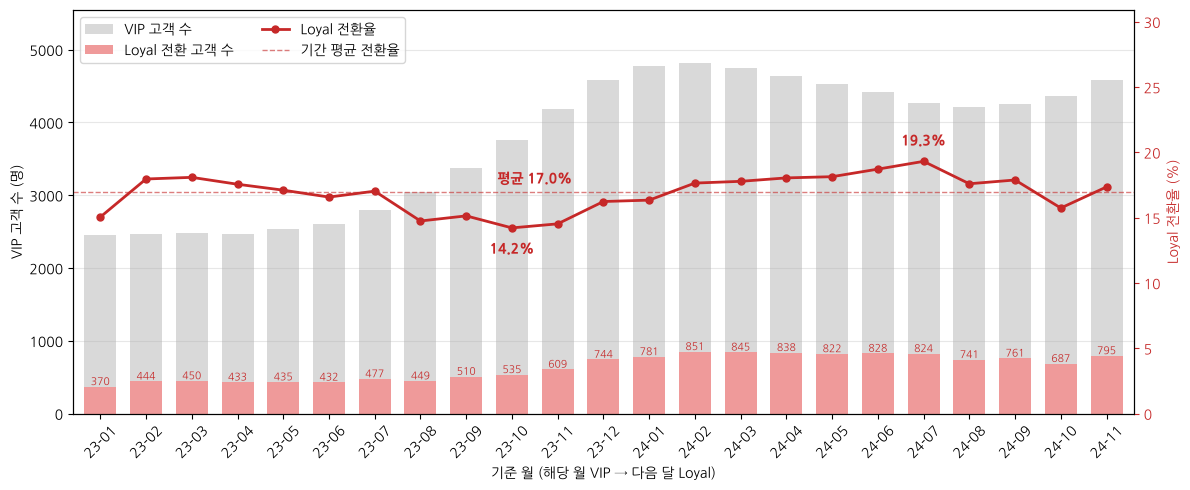

In [8]:
monthly_rate = (
    vip.groupby('year_month')
    .agg(vip_customers=('user_id', 'size'), demoted_customers=('demoted', 'sum'), demotion_rate=('demoted', 'mean'))
    .reset_index()
)
monthly_rate['demotion_rate'] *= 100
monthly_rate['label'] = monthly_rate['year_month'].dt.strftime('%y-%m')
baseline_rate = vip['demoted'].mean() * 100
COLOR_CONVERT = '#C62828'      # Loyal 전환율 (빨간색)
COLOR_CONVERT_BAR = '#EF9A9A'  # Loyal 전환 고객 수 막대 (같은 빨간색 계열, 선과 구분되도록 연하게)

fig, ax1 = plt.subplots(figsize=(12, 5))
x = np.arange(len(monthly_rate))

# 왼쪽 축: 월별 VIP 고객 수
ax1.bar(x, monthly_rate['vip_customers'], width=0.7, color=COLOR_BASELINE, label='VIP 고객 수')
ax1.bar(x, monthly_rate['demoted_customers'], width=0.7, color=COLOR_CONVERT_BAR, label='Loyal 전환 고객 수')
for xi, n in zip(x, monthly_rate['demoted_customers']):
    ax1.text(xi, n, f'{n:,}', ha='center', va='bottom', fontsize=7.5, color=COLOR_CONVERT)
ax1.set_ylabel('VIP 고객 수 (명)')
ax1.set_ylim(0, monthly_rate['vip_customers'].max() * 1.15)
ax1.set_xticks(x)
ax1.set_xticklabels(monthly_rate['label'], rotation=45)
ax1.set_xlim(-0.6, len(x) - 0.4)
ax1.grid(axis='y', alpha=0.3)

# 오른쪽 축: 다음 달 Loyal 전환율
ax2 = ax1.twinx()
ax2.plot(x, monthly_rate['demotion_rate'], marker='o', markersize=5, color=COLOR_CONVERT, linewidth=2, label='Loyal 전환율')
ax2.axhline(baseline_rate, color=COLOR_CONVERT, linestyle='--', linewidth=1, alpha=0.6, label='기간 평균 전환율')
# 평균값: 전환율이 평균보다 낮은 구간(23-10 ~ 23-11) 위쪽에 표시합니다.
ax2.text(monthly_rate['demotion_rate'].idxmin() + 0.5, baseline_rate + 0.5, f'평균 {baseline_rate:.1f}%',
         ha='center', va='bottom', fontsize=10, weight='bold', color=COLOR_CONVERT)
for idx, va, offset in [(monthly_rate['demotion_rate'].idxmin(), 'top', -10), (monthly_rate['demotion_rate'].idxmax(), 'bottom', 10)]:
    row = monthly_rate.loc[idx]
    ax2.annotate(f"{row['demotion_rate']:.1f}%", (idx, row['demotion_rate']), xytext=(0, offset),
                 textcoords='offset points', ha='center', va=va, fontsize=10, weight='bold', color=COLOR_CONVERT)
ax2.set_ylim(0, monthly_rate['demotion_rate'].max() * 1.6)
ax2.set_ylabel('Loyal 전환율 (%)', color=COLOR_CONVERT)
ax2.tick_params(axis='y', colors=COLOR_CONVERT)

handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(handles, labels, loc='upper left', ncol=2)

# 시각화 제목: 월별 VIP 고객 수와 Loyal 전환율
plt.title('', fontsize=14, weight='bold')
ax1.set_xlabel('기준 월 (해당 월 VIP → 다음 달 Loyal)')
plt.tight_layout()
plt.show()

### 1.1.3. VIP 고객 구성 월별 추이

- **계산**: 해당 월 진입 성격별 고객 수 ÷ 해당 월 VIP 고객 수

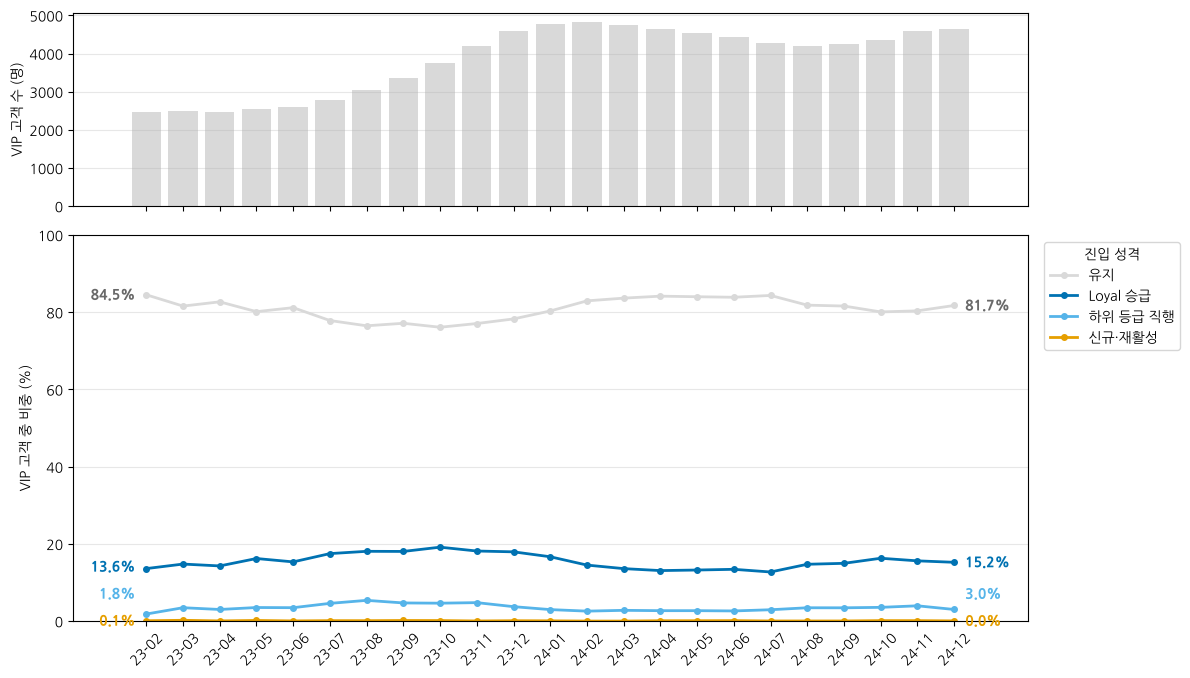

In [9]:
composition = (
    vip_all.loc[vip_all['prev_segment'].notna()]
    .groupby(['year_month', 'entry_type'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=ENTRY_TYPE_ORDER, fill_value=0)
    .rename_axis(columns=None)
)
composition.index = composition.index.strftime('%y-%m')
composition_share = composition.div(composition.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
x = np.arange(len(composition))

# 위: 월별 VIP 고객 수
ax1.bar(x, composition.sum(axis=1), color=COLOR_BASELINE)
ax1.set_ylabel('VIP 고객 수 (명)')
ax1.grid(axis='y', alpha=0.3)

# 아래: 진입 성격별 비중
for entry_type in ENTRY_TYPE_ORDER:
    ax2.plot(x, composition_share[entry_type], marker='o', markersize=4, linewidth=2,
             color=ENTRY_TYPE_COLOR[entry_type], label=entry_type)

y_max = 100
for idx, ha, x_offset in [(0, 'right', -0.3), (len(x) - 1, 'left', 0.3)]:
    values = composition_share.iloc[idx].to_dict()
    positions = spread_labels(values, y_max * 0.07)
    for entry_type, value in values.items():
        ax2.text(x[idx] + x_offset, positions[entry_type], f'{value:.1f}%', ha=ha, va='center', fontsize=10,
                 weight='bold', color=ENTRY_TYPE_COLOR[entry_type] if entry_type != '유지' else 'dimgray')

ax2.set_xticks(x)
ax2.set_xticklabels(composition_share.index, rotation=45)
ax2.set_xlim(-2, len(x) + 1)
ax2.set_ylim(0, y_max)
ax2.set_ylabel('VIP 고객 중 비중 (%)')
ax2.legend(title='진입 성격', bbox_to_anchor=(1.01, 1), loc='upper left')
ax2.grid(axis='y', alpha=0.3)

# 시각화 제목: 월별 VIP 고객 수와 진입 성격별 구성 비중
fig.suptitle('', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

### 1.1.4. VIP → Loyal 강등 원인

강등이 R 저하에 집중되면 개입 기준은 마지막 구매 후 경과일이 됩니다.

- **강등 원인**: 강등된 달에 4 미만으로 떨어진 지표 (`R 저하` / `F 저하` / `M 저하` / `복합 저하`)
- **계산**: 원인별 강등 고객-월 수 ÷ 전체 강등 고객-월 수

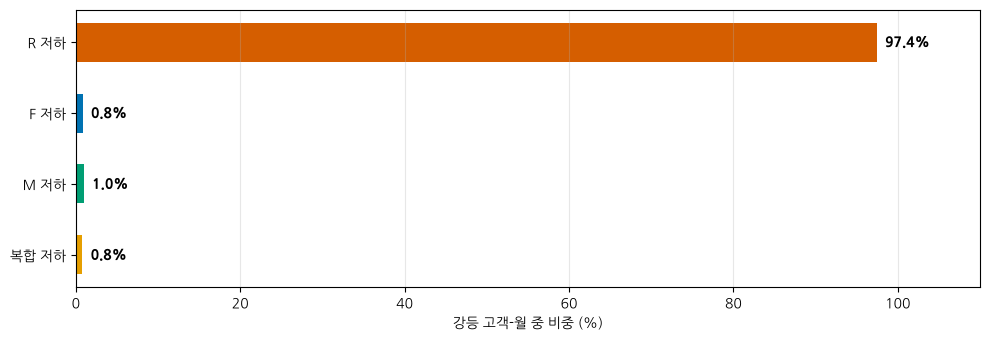

In [10]:

# 강등 고객-월의 강등된 달 점수
score_cols = ['user_id', 'year_month', 'R_score', 'F_score', 'M_score', 'recency_days']
demotion = (
    vip.loc[vip['demoted'], ['user_id', 'year_month', 'recency_days']]
    .rename(columns={'recency_days': 'vip_recency'})
    .assign(year_month=lambda df: df['year_month'] + 1)
    .merge(user_segment[score_cols], on=['user_id', 'year_month'], how='left')
)
drop_flags = pd.DataFrame({
    'R': demotion['R_score'].lt(4),
    'F': demotion['F_score'].lt(4),
    'M': demotion['M_score'].lt(4),
})
demotion['demotion_cause'] = np.select(
    [drop_flags.sum(axis=1).ge(2), drop_flags['R'], drop_flags['F'], drop_flags['M']],
    ['복합 저하', 'R 저하', 'F 저하', 'M 저하'],
    default='기타',
)

CAUSE_ORDER = ['R 저하', 'F 저하', 'M 저하', '복합 저하']
cause_share = demotion['demotion_cause'].value_counts(normalize=True).reindex(CAUSE_ORDER, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(CAUSE_ORDER, cause_share.values, color=[COLOR_AT_RISK, COLOR_RETAINED, COLOR_INTEREST, COLOR_LOW_VALUE], height=0.55)
annotate_barh(ax)
ax.invert_yaxis()
ax.set_xlim(0, 110)

# 시각화 제목: VIP → Loyal 강등 원인 비중
plt.title('', fontsize=14, weight='bold')
plt.xlabel('강등 고객-월 중 비중 (%)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

cause_summary = (
    demotion.groupby('demotion_cause')
    .agg(
        customer_months=('user_id', 'size'),
        vip_recency_median=('vip_recency', 'median'),
        demoted_recency_median=('recency_days', 'median'),
    )
    .reindex(CAUSE_ORDER)
)
cause_summary.insert(1, 'share', cause_summary['customer_months'] / cause_summary['customer_months'].sum() * 100)
cause_summary.columns = ['고객-월 수', '비중(%)', 'VIP 마지막 달 경과일 중앙값', '강등 달 경과일 중앙값']

### 1.1.5. VIP → Loyal 강등 고객의 이후 경로

- **대상**: 강등 고객-월 (강등 월 2023-02 ~ 2024-05)
- **판정**: 강등 후 7개월 안에 처음 이동한 세그먼트 (`VIP 재승급` / `At_Risk 진입` / `Loyal 유지` / `기타`)
- **관측 기간 7개월**: 경과일 0일 근처에서 강등된 고객이 At_Risk(180일 초과)에 도달하는 약 6개월 + 월말 판정 차이 1개월

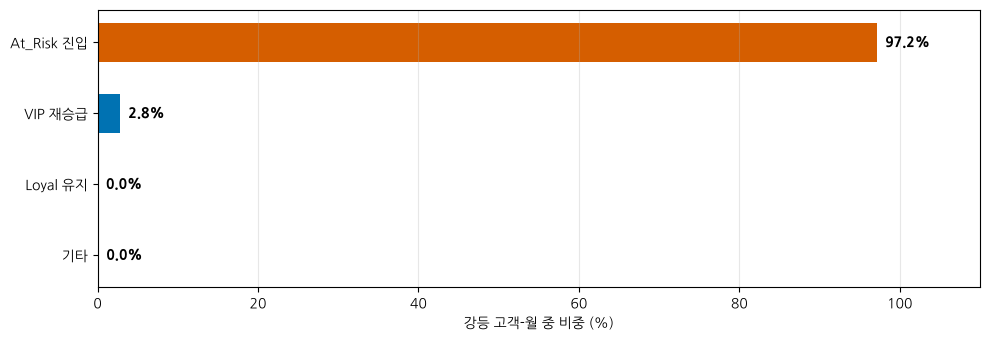

In [11]:
TRACE_MONTHS = 7

# 고객별 월별 세그먼트 매트릭스
segment_matrix = user_segment.pivot(index='user_id', columns='year_month', values='segment')
last_snapshot = segment_matrix.columns.max()

# 강등 월 = VIP 마지막 달 + 1
demoted = vip.loc[vip['demoted'], ['user_id', 'year_month', 'monetary']].copy()
demoted['demoted_month'] = demoted['year_month'] + 1
demoted = demoted.loc[demoted['demoted_month'] <= last_snapshot - TRACE_MONTHS]


def trace_after_demotion(user_id, demoted_month, horizon=TRACE_MONTHS):
    # 강등 후 horizon개월 안에 처음 이동한 세그먼트를 반환합니다. 계속 Loyal이면 'Loyal'을 반환합니다.
    for k in range(1, horizon + 1):
        segment = segment_matrix.at[user_id, demoted_month + k]
        if segment != 'Loyal':
            return segment
    return 'Loyal'


demoted['after_segment'] = [
    trace_after_demotion(user_id, month)
    for user_id, month in zip(demoted['user_id'], demoted['demoted_month'])
]
OUTCOME_MAP = {'Loyal': 'Loyal 유지', 'VIP': 'VIP 재승급', 'At_Risk': 'At_Risk 진입'}
OUTCOME_ORDER = ['At_Risk 진입', 'VIP 재승급', 'Loyal 유지', '기타']
OUTCOME_COLOR = {'At_Risk 진입': COLOR_AT_RISK, 'VIP 재승급': COLOR_RETAINED, 'Loyal 유지': COLOR_BASELINE, '기타': COLOR_LOW_VALUE}
demoted['outcome'] = demoted['after_segment'].map(OUTCOME_MAP).fillna('기타')
outcome_share = demoted['outcome'].value_counts(normalize=True).reindex(OUTCOME_ORDER, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(OUTCOME_ORDER, outcome_share.values, color=[OUTCOME_COLOR[o] for o in OUTCOME_ORDER], height=0.55)
annotate_barh(ax)
ax.invert_yaxis()
ax.set_xlim(0, 110)

# 시각화 제목: VIP 강등 고객의 강등 후 7개월 경로
plt.title('', fontsize=14, weight='bold')
plt.xlabel('강등 고객-월 중 비중 (%)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.1.6. VIP 구간 주별 플랫폼 활동 비율

강등 고객에게 강등 전 `VIP` 구간(마지막 구매 후 1~90일)에 플랫폼 접점이 남아 있는지 확인합니다.

- **대상**: 1-5의 강등 건 중 강등된 달의 경과일이 90일 초과인 건 (VIP 구간 전체를 관측 가능)
- **계산**: 해당 주에 시작한 세션이 1개 이상 있는 건 ÷ 대상 건 (마지막 구매 다음 날부터 7일 단위, 마지막 구매 세션 제외)

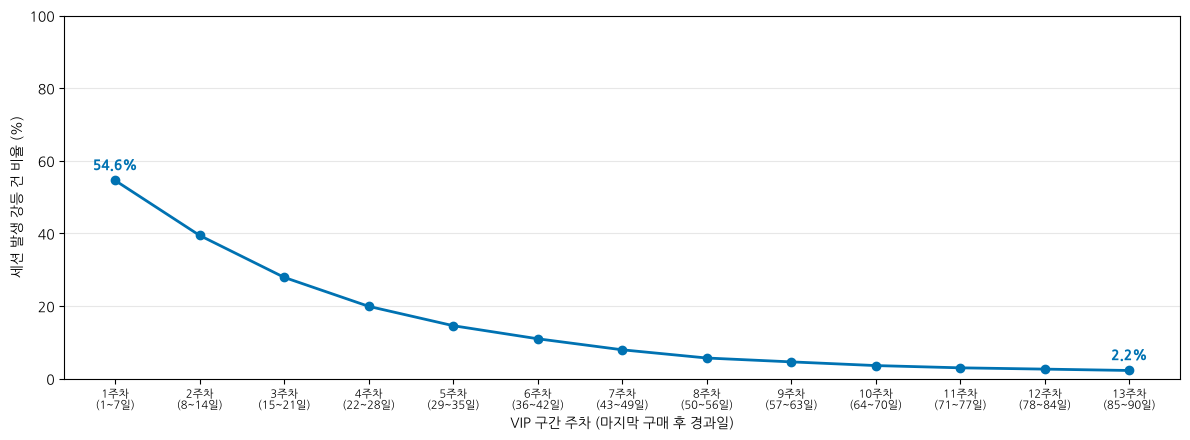

In [12]:
VIP_END, LOYAL_END = 90, 180   # 마지막 구매 후 경과일: VIP 구간 (0, 90], Loyal 구간 (90, 180]
N_WEEKS = 13

# 대상: VIP → Loyal 강등 건 전체 중 강등된 달의 경과일이 90일을 넘은 건
signal_cohort = demoted.merge(
    vip[['user_id', 'year_month', 'last_order_dt', 'next_recency']], on=['user_id', 'year_month'], how='left'
)
signal_cohort = signal_cohort.loc[signal_cohort['next_recency'].gt(VIP_END)].reset_index(drop=True)
signal_cohort['case_id'] = signal_cohort.index

# Loyal 구간이 끝나는 경과일: 다음 유효 구매일(구간 안에서 재구매한 경우) 또는 180일
cohort_orders = oi_orders.merge(signal_cohort[['case_id', 'user_id', 'last_order_dt']], on='user_id')
cohort_orders['elapsed_days'] = (cohort_orders['created_at'] - cohort_orders['last_order_dt']).dt.total_seconds() / 86400
next_order_days = cohort_orders.loc[cohort_orders['elapsed_days'].gt(0)].groupby('case_id')['elapsed_days'].min()
signal_cohort['loyal_end_days'] = signal_cohort['case_id'].map(next_order_days).clip(upper=LOYAL_END).fillna(LOYAL_END)

# 대상 고객의 행동 로그 → 세션 시작 경과일(마지막 구매 기준)
cohort_events = events.loc[
    events['user_id'].isin(signal_cohort['user_id'].unique()), ['user_id', 'session_id', 'created_at']
].merge(signal_cohort[['case_id', 'user_id', 'last_order_dt']], on='user_id')
cohort_events['elapsed_days'] = (cohort_events['created_at'] - cohort_events['last_order_dt']).dt.total_seconds() / 86400
cohort_sessions = (
    cohort_events.groupby(['case_id', 'session_id'], as_index=False)['elapsed_days'].min()
    .rename(columns={'elapsed_days': 'session_start_days'})
)
del cohort_events


def weekly_active_rate(start, end, case_end=None):
    # (start, end] 구간에 시작한 세션을 7일 단위 주차로 묶어 주별 활동 강등 건 비율(%)을 반환합니다.
    # case_end(건별 구간 종료 경과일)가 주어지면, 각 주의 분모는 그 주 시작 시점에 아직 구간에 남아 있는 건이고
    # 종료(재구매) 이후의 세션은 세지 않습니다.
    if case_end is None:
        case_end = pd.Series(end, index=signal_cohort['case_id'])
    s = cohort_sessions.loc[cohort_sessions['session_start_days'].gt(start) & cohort_sessions['session_start_days'].le(end)].copy()
    s = s.loc[s['session_start_days'].le(s['case_id'].map(case_end))]
    s['week'] = np.ceil((s['session_start_days'] - start) / 7).astype(int).clip(1, N_WEEKS)
    week_start = {w: start + 7 * (w - 1) for w in range(1, N_WEEKS + 1)}
    at_risk = pd.Series({w: case_end.gt(week_start[w]).sum() for w in week_start})
    rate = s.groupby('week')['case_id'].nunique().reindex(range(1, N_WEEKS + 1), fill_value=0) / at_risk * 100
    return rate, s['case_id'].nunique() / len(signal_cohort) * 100, at_risk


def plot_weekly(rate, start, end, color, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(12, 4.5))
    weeks = range(1, N_WEEKS + 1)
    ax.plot(weeks, rate.values, marker='o', color=color, linewidth=2)
    for w in [1, N_WEEKS]:
        ax.annotate(f'{rate[w]:.1f}%', (w, rate[w]), xytext=(0, 8), textcoords='offset points',
                    ha='center', fontsize=10, weight='bold', color=color)
    ax.set_xticks(list(weeks))
    ax.set_xticklabels([f'{w}주차\n({start + 7 * (w - 1) + 1}~{min(start + 7 * w, end)}일)' for w in weeks], fontsize=8)
    ax.set_ylim(0, 100)   # 1-6·1-7을 같은 눈금으로 비교합니다.
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.3)
    return fig, ax


vip_weekly, vip_any, _ = weekly_active_rate(0, VIP_END)
fig, ax = plot_weekly(vip_weekly, 0, VIP_END, COLOR_RETAINED, 'VIP 구간 주차 (마지막 구매 후 경과일)', '세션 발생 강등 건 비율 (%)')

# 시각화 제목: VIP 단계 마지막 구매 후 주별 플랫폼 활동 비율 (Loyal 진입 전)
plt.title('', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

### 1.1.7. Loyal 구간 주별 플랫폼 활동 비율

- **대상**: 1-6과 같음
- **`Loyal` 구간**: 마지막 구매 후 91~180일. 구간 안에서 재구매하면 그 시점에 구간이 끝난 것으로 보고 이후 주의 분모에서 제외
- **계산**: 해당 주에 시작한 세션이 1개 이상 있는 건 ÷ 그 주에 아직 `Loyal` 구간에 있는 건

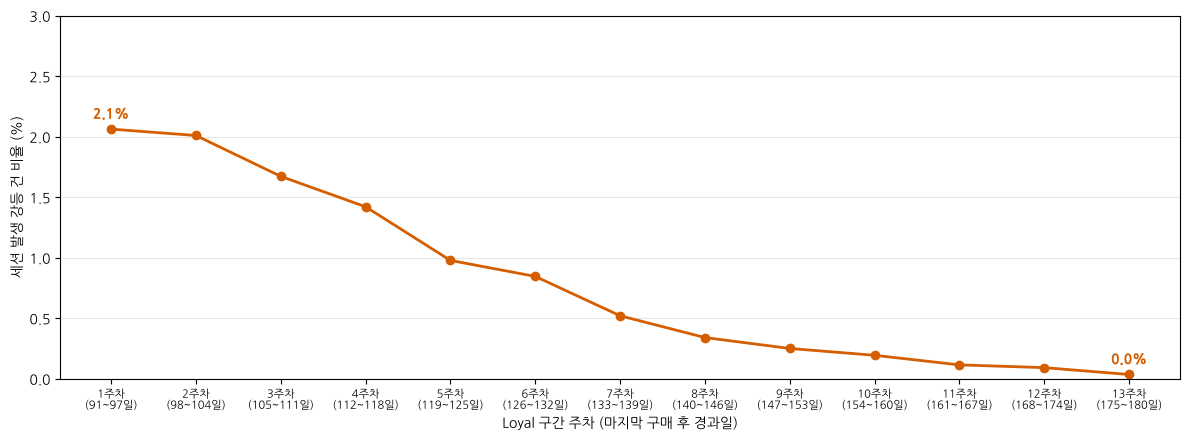

In [13]:
loyal_end = signal_cohort.set_index('case_id')['loyal_end_days']
loyal_weekly, loyal_any, loyal_at_risk = weekly_active_rate(VIP_END, LOYAL_END, case_end=loyal_end)
fig, ax = plot_weekly(loyal_weekly, VIP_END, LOYAL_END, COLOR_AT_RISK, 'Loyal 구간 주차 (마지막 구매 후 경과일)', '세션 발생 강등 건 비율 (%)')

# 시각화 제목: VIP → Loyal 진입 고객의 주별 플랫폼 활동 비율 (Loyal 구간, At_Risk 진입 전)
plt.ylim(0, 3)
plt.title('', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

### 1.1.8. Loyal 구간 주별 플랫폼 활동 비율 — `At_Risk` 진입 고객

1-7에는 `Loyal` 구간에서 재구매해 `VIP`로 돌아간 고객의 활동이 섞여 있어, `At_Risk`로 떨어진 고객만 따로 봅니다.

- **대상**: 1-7의 대상 중 강등 후 7개월 안에 `At_Risk`로 진입한 건

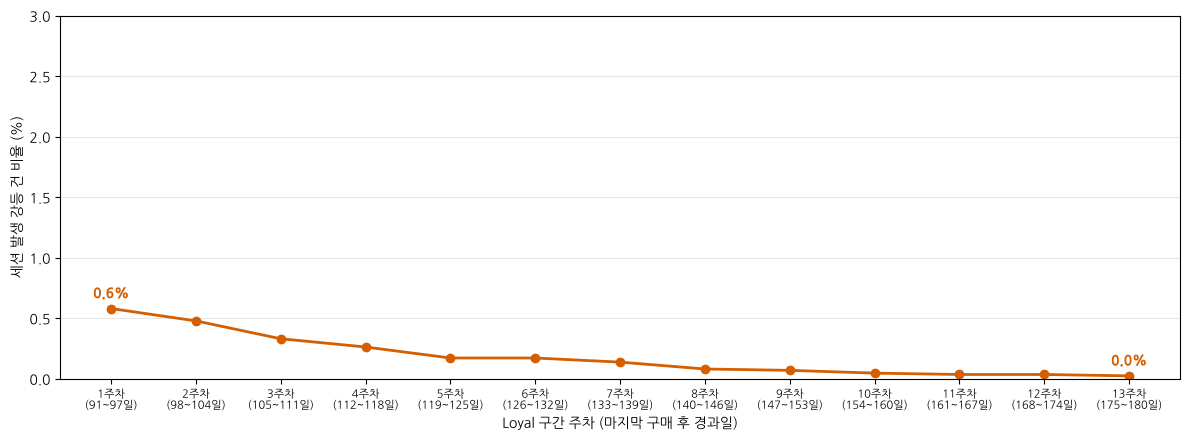

In [14]:
# 대상: 1-7의 대상 중 At_Risk 진입 건
atrisk_ids = signal_cohort.loc[signal_cohort['outcome'].eq('At_Risk 진입'), 'case_id']
atrisk_end = loyal_end.loc[atrisk_ids]
atrisk_weekly, _, atrisk_at_risk = weekly_active_rate(VIP_END, LOYAL_END, case_end=atrisk_end)

fig, ax = plot_weekly(atrisk_weekly, VIP_END, LOYAL_END, COLOR_AT_RISK, 'Loyal 구간 주차 (마지막 구매 후 경과일)', '세션 발생 강등 건 비율 (%)')

# 시각화 제목: VIP → Loyal 진입 후 At_Risk로 떨어지는 고객의 주별 플랫폼 활동 비율 (Loyal 구간)
plt.ylim(0, 3)
plt.title('', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

## 1.2. 개입 시점 설정

VIP 강등은 대부분 R 저하(1-4)이므로 경과일 기준으로 개입 시점을 정합니다. 먼저 개인 구매 주기를 기준으로 쓸 수 있는지 확인하고(2-1·2-2), 이어서 전체 고객 기준 경과일로 1차 시점(2-3~2-5)과 3차 시점(2-6)을 정합니다.

### 1.2.1. VIP 진입 시점 구매 간격 개수

개인 주기를 추정할 만큼 구매 이력이 있는지 확인합니다.

- **대상**: 진입 월 2023-02 ~ 2024-12인 VIP 구간
- **계산**: 진입 월말 기준 최근 365일 주문 수 − 1

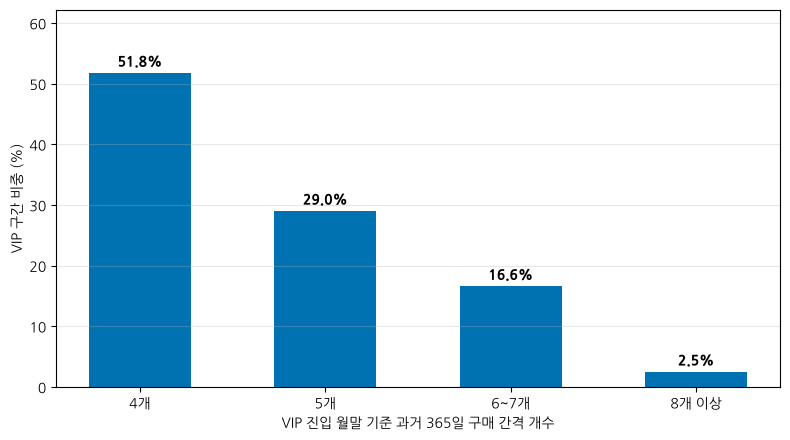

In [15]:
# VIP 구간별 진입 월 (2023-01부터 이어진 구간은 진입 시점을 알 수 없어 제외)
spell_entry = (
    vip_all.groupby(['user_id', 'spell_id'], as_index=False)
    .agg(entry_month=('year_month', 'min'), entry_prev_segment=('prev_segment', lambda s: s.iloc[0]))
)
vip_spells = (
    spell_entry.loc[spell_entry['entry_prev_segment'].notna()]
    .reset_index(drop=True)
    .rename_axis('spell_key')
    .reset_index()
)
vip_spells['window_end'] = (vip_spells['entry_month'] + 1).dt.to_timestamp()
vip_spells['window_start'] = vip_spells['window_end'] - pd.Timedelta(days=365)

# VIP 진입 월말 기준 최근 365일 주문으로 구매 간격을 계산합니다.
spell_orders = oi_orders.merge(vip_spells[['spell_key', 'user_id', 'window_start', 'window_end']], on='user_id')
spell_orders = spell_orders.loc[
    (spell_orders['created_at'] >= spell_orders['window_start'])
    & (spell_orders['created_at'] < spell_orders['window_end'])
].sort_values(['spell_key', 'created_at'])
spell_orders['gap_days'] = spell_orders.groupby('spell_key')['created_at'].diff().dt.total_seconds() / 86400

gap_stats = spell_orders.groupby('spell_key')['gap_days'].agg(['mean', 'std', 'count'])
gap_stats['cv'] = gap_stats['std'] / gap_stats['mean']

# 구매 간격 개수 구간 (VIP는 F≥4이므로 간격은 최소 4개)
GAP_COUNT_LABELS = ['4개', '5개', '6~7개', '8개 이상']
gap_stats['gap_count_group'] = pd.cut(gap_stats['count'], bins=[3, 4, 5, 7, np.inf], labels=GAP_COUNT_LABELS)
gap_count_share = gap_stats['gap_count_group'].value_counts(normalize=True).reindex(GAP_COUNT_LABELS) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(gap_count_share.index.astype(str), gap_count_share.values, color=COLOR_RETAINED, width=0.55)
annotate_bar(ax)

# 시각화 제목: VIP 진입 시점 구매 간격 개수
plt.title('', fontsize=14, weight='bold')
ax.set_xlabel('VIP 진입 월말 기준 과거 365일 구매 간격 개수')
ax.set_ylabel('VIP 구간 비중 (%)')
ax.set_ylim(0, gap_count_share.max() * 1.2)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2.2. VIP 구간의 구매 간격 변동계수(CV) 분포

- **계산**: CV = 구매 간격 표준편차 ÷ 구매 간격 평균
- **판단 기준**: CV가 낮은 영역에 집중되면 개인 주기 기준을 검토하고, 아니면 전체 고객 기준 경과일을 사용합니다.

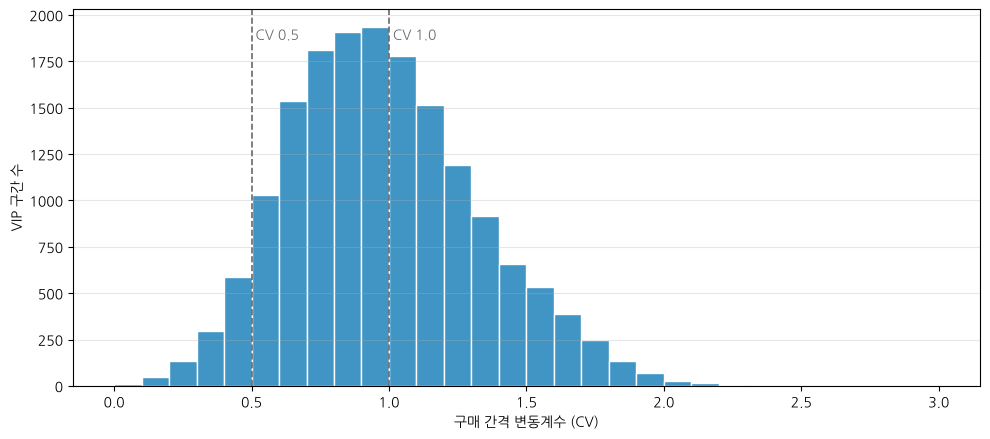

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(gap_stats['cv'], bins=np.arange(0, 3.01, 0.1), color=COLOR_RETAINED, edgecolor='white', ax=ax)
# 참고선: 해석 기준이 아닌 수치 참고용
for ref in (0.5, 1.0):
    ax.axvline(ref, color='dimgray', linestyle='--', linewidth=1.2)
    ax.text(ref, ax.get_ylim()[1] * 0.95, f' CV {ref:.1f}', color='dimgray', va='top')

# 시각화 제목: VIP 구간의 구매 간격 변동계수(CV) 분포
plt.title('', fontsize=14, weight='bold')
ax.set_xlabel('구매 간격 변동계수 (CV)')
ax.set_ylabel('VIP 구간 수')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2.3. 경과일 구간별 다음 달 재구매율

- **계산**: 경과일 구간(15일 단위)별 다음 달 재구매 고객-월 수 ÷ 해당 구간 VIP 고객-월 수
- **보조선**: 60일(한 달 안에 구매가 없으면 다음 달 90일 초과), 90일(VIP 기준)

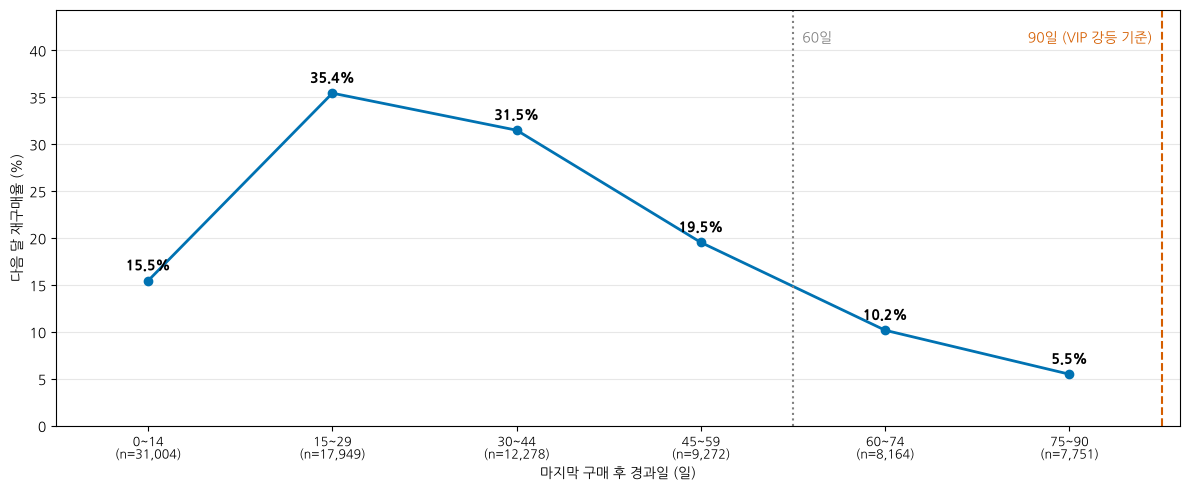

In [17]:
recency_curve = (
    vip.groupby('recency_bin', observed=False)
    .agg(customer_months=('user_id', 'size'), repurchase_rate=('repurchased', 'mean'), demotion_rate=('demoted', 'mean'))
    .reset_index()
)
recency_curve[['repurchase_rate', 'demotion_rate']] *= 100

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(recency_curve))
ax.plot(x, recency_curve['repurchase_rate'], marker='o', color=COLOR_RETAINED, linewidth=2)
for xi, rate in zip(x, recency_curve['repurchase_rate']):
    ax.annotate(f'{rate:.1f}%', (xi, rate), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=10, weight='bold')

ax.set_ylim(0, recency_curve['repurchase_rate'].max() * 1.25)
# 60일(4번째 구간 뒤)과 90일 강등 기준(마지막 구간 뒤)
ax.axvline(3.5, color='gray', linestyle=':', linewidth=1.5)
ax.text(3.55, ax.get_ylim()[1] * 0.95, '60일', color='gray', va='top')
ax.axvline(len(x) - 0.5, color=COLOR_AT_RISK, linestyle='--', linewidth=1.5)
ax.text(len(x) - 0.55, ax.get_ylim()[1] * 0.95, '90일 (VIP 강등 기준)', color=COLOR_AT_RISK, va='top', ha='right')

ax.set_xticks(x)
ax.set_xticklabels([f'{label}\n(n={n:,})' for label, n in zip(recency_curve['recency_bin'], recency_curve['customer_months'])], fontsize=9)
ax.set_xlim(-0.5, len(x) - 0.4)

# 시각화 제목: 경과일 구간별 VIP 고객의 다음 달 재구매율
plt.title('', fontsize=14, weight='bold')
plt.xlabel('마지막 구매 후 경과일 (일)')
plt.ylabel('다음 달 재구매율 (%)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2.4. VIP 유지 고객의 누적 재구매 비율

기준선 후보를 정하기 위해 VIP를 유지한 고객이 보통 며칠 안에 재구매하는지 확인합니다.

- **분석 단위**: VIP 스냅샷의 마지막 구매 1건(구매 건). 같은 고객도 재구매마다 새 건
- **강등 판정 시점**: 경과일이 처음 90일을 넘는 월말 스냅샷 (마지막 구매 후 약 91~122일)
- **[주의]** VIP 유지 여부는 이후 재구매로 정해지므로 이 분포는 기준선 후보를 정하는 데만 쓰고, 규칙 성능은 2-5에서 전체 구매 건으로 평가합니다.

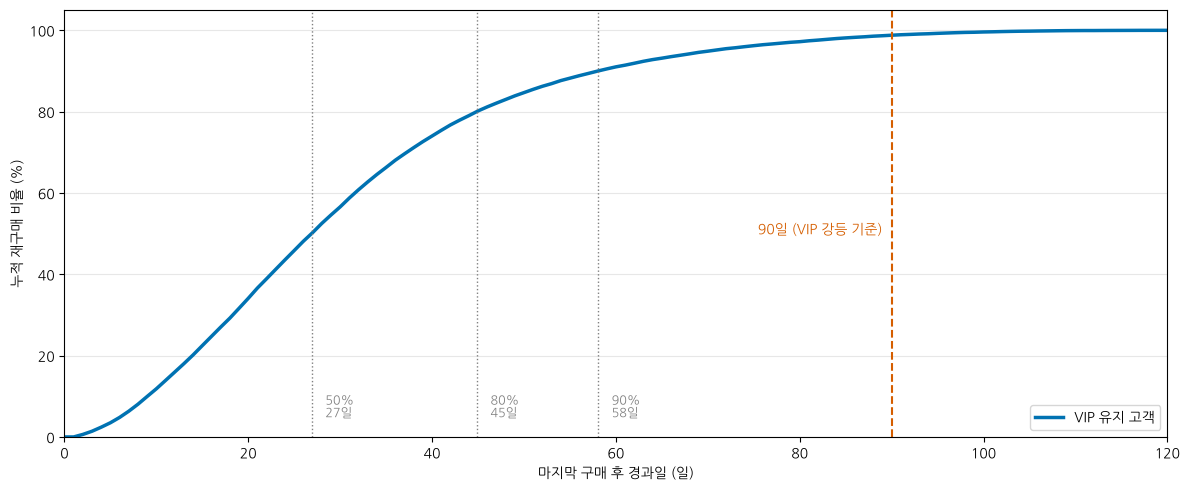

In [18]:
# VIP 구매 건: VIP 스냅샷의 (고객, 마지막 구매일) 조합. 처음 관측된 달을 남깁니다.
episodes = (
    user_segment.loc[user_segment['segment'].eq('VIP'), ['user_id', 'year_month', 'last_order_dt']]
    .sort_values('year_month')
    .drop_duplicates(['user_id', 'last_order_dt'])
    .rename(columns={'year_month': 'first_seen_month'})
    .reset_index(drop=True)
)

# 강등 판정 시점: 경과일(다음 달 1일 - 마지막 구매일, 일 단위 내림)이 처음 90일을 넘는 월말 스냅샷
# 경과일 > 90  ⇔  다음 달 1일 ≥ 마지막 구매일 + 91일
deadline_point = episodes['last_order_dt'] + pd.Timedelta(days=91)
deadline_period = deadline_point.dt.to_period('M')
on_month_start = deadline_point.eq(deadline_period.dt.to_timestamp())
episodes['check_month'] = deadline_period - on_month_start.astype(int)
episodes['days_to_check'] = (
    (episodes['check_month'] + 1).dt.to_timestamp() - episodes['last_order_dt']
).dt.total_seconds() / 86400

# 강등 판정 시점이 관측 기간(2024-12) 안에 있는 구매 건만 사용합니다.
episodes = episodes.loc[episodes['check_month'] <= last_snapshot].reset_index(drop=True)
episodes['check_segment'] = [segment_matrix.at[u, m] for u, m in zip(episodes['user_id'], episodes['check_month'])]
episodes['outcome'] = np.where(episodes['check_segment'].eq('VIP'), 'VIP 유지', '강등')

# 마지막 구매일 이후 첫 구매까지 걸린 일수
episodes['row_key'] = episodes.index
next_orders = oi_orders.merge(episodes[['row_key', 'user_id', 'last_order_dt']], on='user_id')
next_orders = next_orders.loc[next_orders['created_at'] > next_orders['last_order_dt']]
first_next = next_orders.groupby('row_key')['created_at'].min()
episodes['days_to_next'] = (episodes['row_key'].map(first_next) - episodes['last_order_dt']).dt.total_seconds() / 86400

normal = episodes.loc[episodes['outcome'].eq('VIP 유지')]

# VIP 유지 고객의 누적 재구매 비율 (경과일 d일 안에 재구매한 비율)
days = np.arange(0, 121)
cum_curve = pd.DataFrame({'days': days})
cum_curve['VIP 유지'] = [(normal['days_to_next'] <= d).mean() * 100 for d in days]
normal_q = normal['days_to_next'].quantile([0.5, 0.8, 0.9])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(cum_curve['days'], cum_curve['VIP 유지'], color=COLOR_RETAINED, linewidth=2.5, label='VIP 유지 고객')
for q, label in zip(normal_q.values, ['50%', '80%', '90%']):
    ax.axvline(q, color='gray', linestyle=':', linewidth=1)
    ax.text(q + 1.5, 5, f'{label}\n{q:.0f}일', color='gray', fontsize=9)
ax.axvline(90, color=COLOR_AT_RISK, linestyle='--', linewidth=1.5)
ax.text(89, 50, '90일 (VIP 강등 기준)', color=COLOR_AT_RISK, ha='right')

# 시각화 제목: VIP 유지 고객의 마지막 구매 후 누적 재구매 비율
plt.title('', fontsize=14, weight='bold')
plt.xlabel('마지막 구매 후 경과일 (일)')
plt.ylabel('누적 재구매 비율 (%)')
plt.xlim(0, 120)
plt.ylim(0, 105)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2.5. 기준선별 개입 규칙 평가

- **개입 규칙**: 마지막 구매 후 T일까지 재구매가 없으면 개입 대상
- **평가 지표**
    - `VIP 유지 고객 포함률`: 대상에 포함된 VIP 유지 건 ÷ VIP 유지 건 (앞당길 때의 비용)
    - `대상 중 강등 비율`: 대상 중 강등 건 ÷ 대상 건 (대상의 위험 수준)
    - `강등까지 남은 일수`: 강등 판정까지 일수 − T의 중앙값 (대응 가능한 시간)

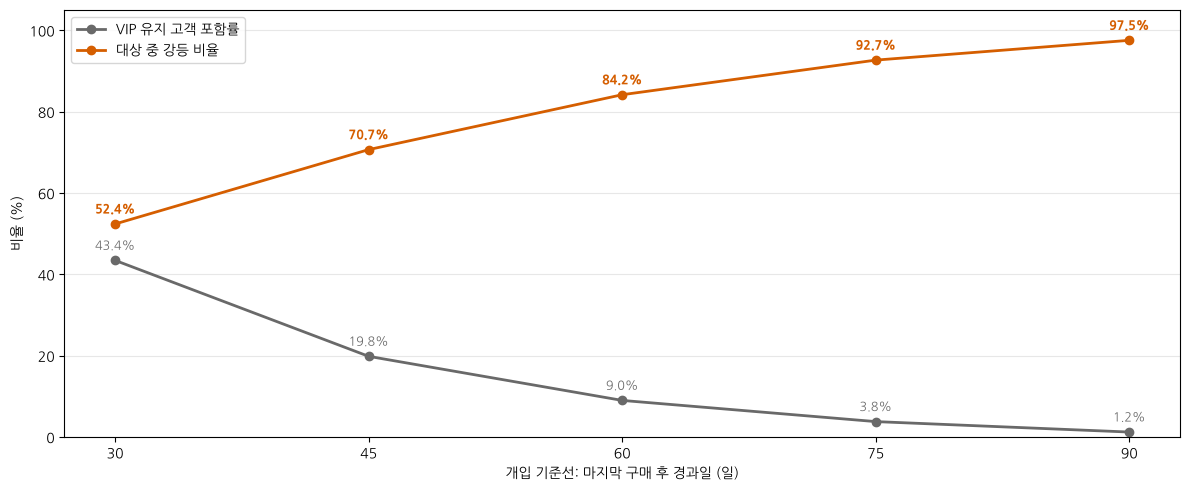

In [19]:
# 기준선 T일별 규칙 평가 (2-4의 episodes, normal 사용)
THRESHOLDS = [30, 45, 60, 75, 90]
rule_eval = []
for t in THRESHOLDS:
    flagged = episodes['days_to_next'].isna() | (episodes['days_to_next'] > t)
    normal_flagged = normal['days_to_next'].isna() | (normal['days_to_next'] > t)
    rule_eval.append({
        '기준선(일)': t,
        '개입 대상 비율(%)': flagged.mean() * 100,
        'VIP 유지 고객 포함률(%)': normal_flagged.mean() * 100,
        '대상 중 강등 비율(%)': episodes.loc[flagged, 'outcome'].eq('강등').mean() * 100,
        '강등까지 남은 일수(중앙값)': (episodes.loc[flagged, 'days_to_check'] - t).median(),
    })
rule_eval = pd.DataFrame(rule_eval)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(rule_eval['기준선(일)'], rule_eval['VIP 유지 고객 포함률(%)'], marker='o', linewidth=2, color='dimgray', label='VIP 유지 고객 포함률')
ax.plot(rule_eval['기준선(일)'], rule_eval['대상 중 강등 비율(%)'], marker='o', linewidth=2, color=COLOR_AT_RISK, label='대상 중 강등 비율')
for _, row in rule_eval.iterrows():
    ax.annotate(f"{row['VIP 유지 고객 포함률(%)']:.1f}%", (row['기준선(일)'], row['VIP 유지 고객 포함률(%)']),
                xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9, color='dimgray')
    ax.annotate(f"{row['대상 중 강등 비율(%)']:.1f}%", (row['기준선(일)'], row['대상 중 강등 비율(%)']),
                xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9, color=COLOR_AT_RISK, weight='bold')
ax.set_xticks(THRESHOLDS)

# 시각화 제목: 기준선별 VIP 유지 고객 포함률과 대상 중 강등 비율
plt.title('', fontsize=14, weight='bold')
plt.xlabel('개입 기준선: 마지막 구매 후 경과일 (일)')
plt.ylabel('비율 (%)')
plt.ylim(0, 105)
plt.legend(loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2.6. 3차 개입 시점 — 강등 후 자연 재구매 시점

할인이 들어가는 3차는 스스로 복귀하는 고객이 대부분 재구매를 마친 뒤에 보냅니다.

- **대상**: 2-4의 강등 건 중 판정 시점까지 구매가 없는 건 (180일까지 관측 가능하도록 판정 월 2024-06 이하)
- **판정 후 일수**: 다음 구매까지 일수 − 강등 판정까지 일수 (`Loyal` 구간 안의 재구매만)
- **3차 시점**: 판정 다음 월말. 이때까지 재구매가 없는 건을 3차 대상으로 보고 이후 자연 재구매율을 계산

In [20]:
LOYAL_END_DAY = 180
demoted_ep = episodes.loc[
    episodes['outcome'].eq('강등')
    & episodes['check_month'].le(pd.Period('2024-06', 'M'))
    & (episodes['days_to_next'].isna() | episodes['days_to_next'].gt(episodes['days_to_check']))
].copy()
demoted_ep['after_check'] = demoted_ep['days_to_next'] - demoted_ep['days_to_check']
demoted_ep['repurchased_loyal'] = demoted_ep['days_to_next'].le(LOYAL_END_DAY)
self_return = demoted_ep.loc[demoted_ep['repurchased_loyal'], 'after_check']

# 3차 시점: 판정 다음 월말 (판정 후 다음 달 일수만큼 경과)
demoted_ep['days_to_third'] = (
    (demoted_ep['check_month'] + 2).dt.to_timestamp() - (demoted_ep['check_month'] + 1).dt.to_timestamp()
).dt.days
third_target = demoted_ep.loc[~(demoted_ep['repurchased_loyal'] & demoted_ep['after_check'].le(demoted_ep['days_to_third']))]
third_natural_rate = third_target['repurchased_loyal'].mean() * 100
third_remaining = LOYAL_END_DAY - third_target['days_to_check'] - third_target['days_to_third']

third_timing = pd.DataFrame({
    '판정 후 일수': [7, 14, 30, 45],
    '스스로 재구매한 건 중 누적 비율(%)': [(self_return <= d).mean() * 100 for d in (7, 14, 30, 45)],
}).round(1)

print(f"강등 건(판정 시점까지 구매 없음): {len(demoted_ep):,}건")
print(f"  Loyal 구간 안에서 스스로 재구매: {len(self_return):,}건 ({len(self_return) / len(demoted_ep) * 100:.2f}%)")
print(f"3차 대상(판정 다음 월말까지 재구매 없음): {len(third_target):,}건")
print(f"  이후 Loyal 구간 자연 재구매율: {third_natural_rate:.2f}%")
print(f"  3차 시점부터 180일까지 남은 일수: 최소 {third_remaining.min():.0f}일, 중앙값 {third_remaining.median():.0f}일, 최대 {third_remaining.max():.0f}일")
third_timing


강등 건(판정 시점까지 구매 없음): 9,970건
  Loyal 구간 안에서 스스로 재구매: 224건 (2.25%)
3차 대상(판정 다음 월말까지 재구매 없음): 9,790건
  이후 Loyal 구간 자연 재구매율: 0.45%
  3차 시점부터 180일까지 남은 일수: 최소 27일, 중앙값 44일, 최대 60일


,판정 후 일수,스스로 재구매한 건 중 누적 비율(%)
0,7,32.1
1,14,51.3
2,30,79.0
3,45,92.4


## 1.3. 관심 신호 유형별 세분화

1차 개입 대상(마지막 구매 후 45일까지 유효 구매가 없는 VIP 구매 건)을 메시지를 나눌 유형으로 구분합니다.

- **판정 기간**: 마지막 구매 후 0~45일에 시작한 세션 (마지막 구매 세션 제외)
- **분석 단위**: 세션 (이벤트 포함 여부만 보고 순서는 보지 않음)
- **[주의]** 비로그인 활동은 연결되지 않으므로 `활동 없음`은 "확인된 활동 없음"입니다. 유형은 메시지 구분 기준이며 강등 위험의 차이를 뜻하지 않습니다.

### 1.3.1. 0~45일 세션의 이벤트 포함 비율

- **계산**: 이벤트 유형별 해당 이벤트가 포함된 세션 수 ÷ 전체 세션 수
- **판단 기준**: 거의 모든 세션에 있는 이벤트는 제외하고, 구매 의도의 깊이를 보여주는 탐색·장바구니·구매를 신호로 사용합니다. 세션이 없으면 `활동 없음`, 세션은 있으나 신호가 없으면 `방문형`

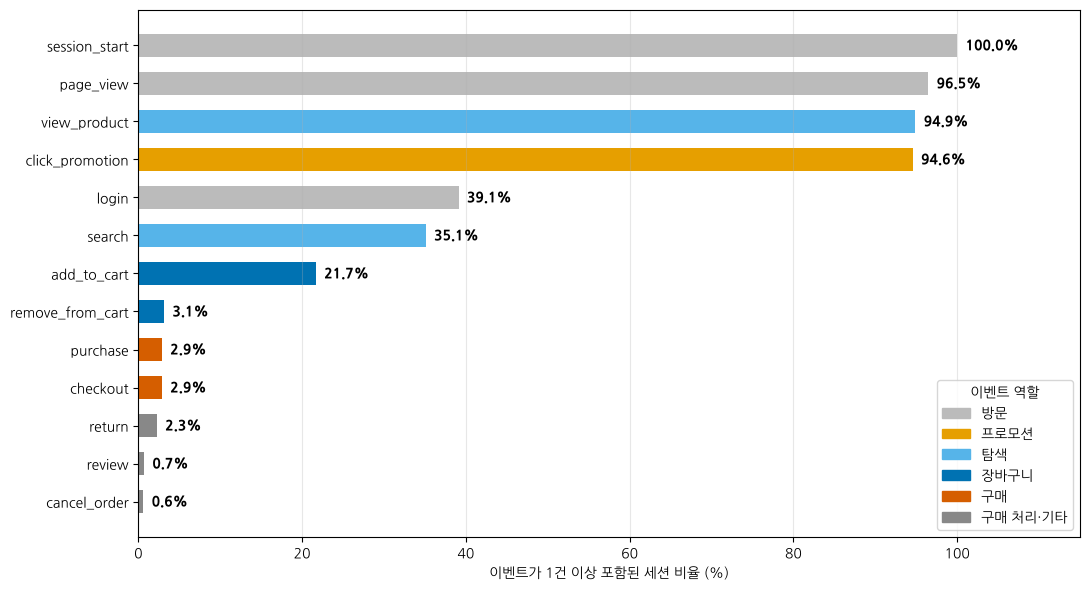

In [21]:
# 개입 시점 대상: 마지막 구매 후 45일(1차 개입 시점)까지 유효 구매가 없는 VIP 구매 건 (2-4의 episodes 사용)
TRIGGER_DAY = 45
episodes['days_to_first_seen'] = (
    (episodes['first_seen_month'] + 1).dt.to_timestamp() - episodes['last_order_dt']
).dt.total_seconds() / 86400
no_purchase = episodes['days_to_next'].isna() | episodes['days_to_next'].gt(TRIGGER_DAY)
trigger = episodes.loc[
    no_purchase & episodes['days_to_first_seen'].le(TRIGGER_DAY), ['row_key', 'user_id', 'last_order_dt', 'outcome']
].copy()

# 0장에서 로드한 행동 로그 중 개입 대상 고객의 이벤트만 사용합니다.
# 마지막 구매 후 경과일과 세션 시작 경과일(세션의 첫 이벤트 기준)
trigger_events = events.loc[events['user_id'].isin(trigger['user_id'].unique())].merge(
    trigger[['row_key', 'user_id', 'last_order_dt']], on='user_id'
)
trigger_events['elapsed_days'] = (trigger_events['created_at'] - trigger_events['last_order_dt']).dt.total_seconds() / 86400
trigger_events['session_start_days'] = trigger_events.groupby(['row_key', 'session_id'])['elapsed_days'].transform('min')
# 판정 기간: 마지막 구매 이후 ~ 45일에 시작한 세션 (마지막 구매가 일어난 세션은 시작 경과일이 0 이하라 제외됩니다)
window_events = trigger_events.loc[trigger_events['session_start_days'].between(0, TRIGGER_DAY, inclusive='right')]
del trigger_events

# 세션 × 이벤트 유형 포함 여부
session_event = pd.crosstab([window_events['row_key'], window_events['session_id']], window_events['event_type']).gt(0)
event_share = session_event.mean().mul(100).sort_values()

EVENT_ROLE = {
    'session_start': '방문', 'login': '방문', 'page_view': '방문',
    'click_promotion': '프로모션',
    'search': '탐색', 'view_product': '탐색',
    'add_to_cart': '장바구니', 'remove_from_cart': '장바구니',
    'checkout': '구매', 'purchase': '구매',
    'return': '구매 처리·기타', 'cancel_order': '구매 처리·기타', 'review': '구매 처리·기타', 'signup': '구매 처리·기타',
}
ROLE_COLOR = {'방문': '#BBBBBB', '프로모션': COLOR_LOW_VALUE, '탐색': '#56B4E9', '장바구니': COLOR_RETAINED,
              '구매': COLOR_AT_RISK, '구매 처리·기타': '#888888'}

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(event_share.index, event_share.values, color=[ROLE_COLOR[EVENT_ROLE.get(e, '구매 처리·기타')] for e in event_share.index], height=0.6)
annotate_barh(ax)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ROLE_COLOR.values()]
ax.legend(handles, ROLE_COLOR.keys(), title='이벤트 역할', loc='lower right')
ax.set_xlim(0, 115)

# 시각화 제목: 개입 시점 대상의 0~45일 세션 이벤트 유형별 포함 비율
plt.title('', fontsize=14, weight='bold')
plt.xlabel('이벤트가 1건 이상 포함된 세션 비율 (%)')
plt.ylabel('')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# 판정 기간(0~45일) 활동 여부 → 활동 없음 정의
active_keys = session_event.index.get_level_values('row_key').unique()
trigger['active'] = trigger['row_key'].isin(active_keys)

### 1.3.2. 신호 간 포함 관계 — 탐색 → 장바구니 → 구매

| 신호 | 포함 이벤트 |
|---|---|
| 탐색 | `search` · `view_product` |
| 장바구니 | `add_to_cart` · `remove_from_cart` |
| 구매 | `checkout` · `purchase` |

- **판단 기준**: 단계를 건너뛴 세션이 거의 없으면 가장 깊은 세션 하나로 유형을 정합니다.

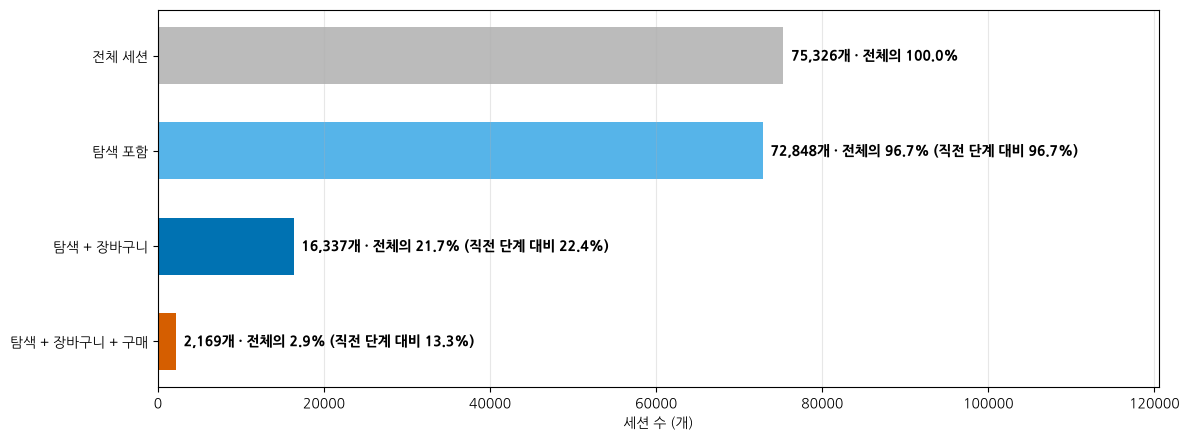

In [22]:
SIGNAL_EVENTS = {
    'explore': ['search', 'view_product'],
    'cart': ['add_to_cart', 'remove_from_cart'],
    'purchase': ['checkout', 'purchase'],
}
session_flags = pd.DataFrame({
    signal: session_event.reindex(columns=event_types, fill_value=False).any(axis=1)
    for signal, event_types in SIGNAL_EVENTS.items()
})

funnel = pd.Series({
    '전체 세션': len(session_flags),
    '탐색 포함': session_flags['explore'].sum(),
    '탐색 + 장바구니': (session_flags['explore'] & session_flags['cart']).sum(),
    '탐색 + 장바구니 + 구매': (session_flags['explore'] & session_flags['cart'] & session_flags['purchase']).sum(),
})
FUNNEL_COLOR = ['#BBBBBB', '#56B4E9', COLOR_RETAINED, COLOR_AT_RISK]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.barh(range(len(funnel)), funnel.values, color=FUNNEL_COLOR, height=0.6)
for y, (label, n) in enumerate(funnel.items()):
    note = '' if y == 0 else f' (직전 단계 대비 {n / funnel.iloc[y - 1] * 100:.1f}%)'
    ax.text(n, y, f'  {n:,}개 · 전체의 {n / funnel.iloc[0] * 100:.1f}%{note}', va='center', fontsize=10, weight='bold')
ax.set_yticks(range(len(funnel)))
ax.set_yticklabels(funnel.index)
ax.invert_yaxis()
ax.set_xlim(0, funnel.iloc[0] * 1.6)

# 시각화 제목: 0~45일 세션의 탐색 → 장바구니 → 구매 단계
plt.title('', fontsize=14, weight='bold')
plt.xlabel('세션 수 (개)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.3.3. 구매 포함 세션의 주문 상태

대상은 45일까지 유효 구매가 없는데 구매 세션이 있는 건의 주문 상태를 확인합니다.

- **연결**: `purchase` 이벤트 시각과 주문 생성 시각이 같은 주문
- **판단 기준**: 대부분 반품·취소이면 `구매 반품·취소형`으로 분리합니다.

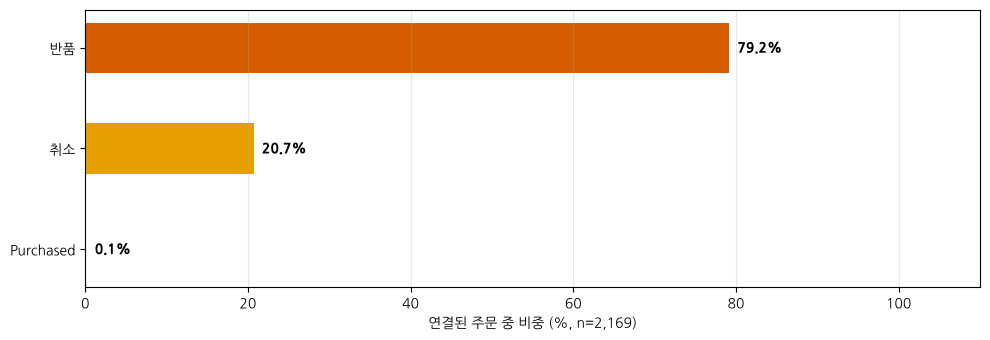

In [23]:
purchase_keys = session_flags.index[session_flags['purchase']].to_frame(index=False)
purchase_events = (
    window_events.loc[window_events['event_type'].eq('purchase'), ['row_key', 'session_id', 'user_id', 'created_at', 'elapsed_days']]
    .merge(purchase_keys, on=['row_key', 'session_id'])
)

# 주문 상태: 주문 아이템 상태를 주문 단위로 묶습니다.
order_status = pd.read_csv(ORDER_ITEMS_PATH, usecols=['order_id', 'user_id', 'status', 'created_at'], parse_dates=['created_at'])
order_status = order_status.loc[order_status['user_id'].isin(purchase_events['user_id'])]
order_status = (
    order_status.groupby(['user_id', 'order_id'])
    .agg(created_at=('created_at', 'min'), status=('status', lambda s: ' · '.join(sorted(set(s)))))
    .reset_index()
)
STATUS_LABEL = {'Returned': '반품', 'Cancelled': '취소'}
matched = purchase_events.merge(order_status, on=['user_id', 'created_at'], how='left')
matched['status_label'] = matched['status'].map(STATUS_LABEL).fillna(matched['status'].fillna('연결 안 됨'))
status_share = matched['status_label'].value_counts(normalize=True).mul(100)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(status_share.index, status_share.values, color=[COLOR_AT_RISK if s == '반품' else COLOR_LOW_VALUE for s in status_share.index], height=0.5)
annotate_barh(ax)
ax.invert_yaxis()
ax.set_xlim(0, 110)

# 시각화 제목: 0~45일 구매 세션 주문의 상태
plt.title('', fontsize=14, weight='bold')
plt.xlabel(f'연결된 주문 중 비중 (%, n={matched["order_id"].notna().sum():,})')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.3.4. 개입 시점 대상 고객의 관심 신호 유형

| 유형 | 정의 (0~45일 세션 기준) |
|---|---|
| 활동 없음 | 세션 없음 |
| 방문형 | 세션은 있으나 탐색·장바구니·구매 신호 없음 |
| 탐색형 | 가장 깊은 세션이 탐색 |
| 관심 상품 탐색형(장바구니) | 가장 깊은 세션이 장바구니 |
| 구매 반품·취소형 | 구매 세션 있음 (주문은 반품·취소) |

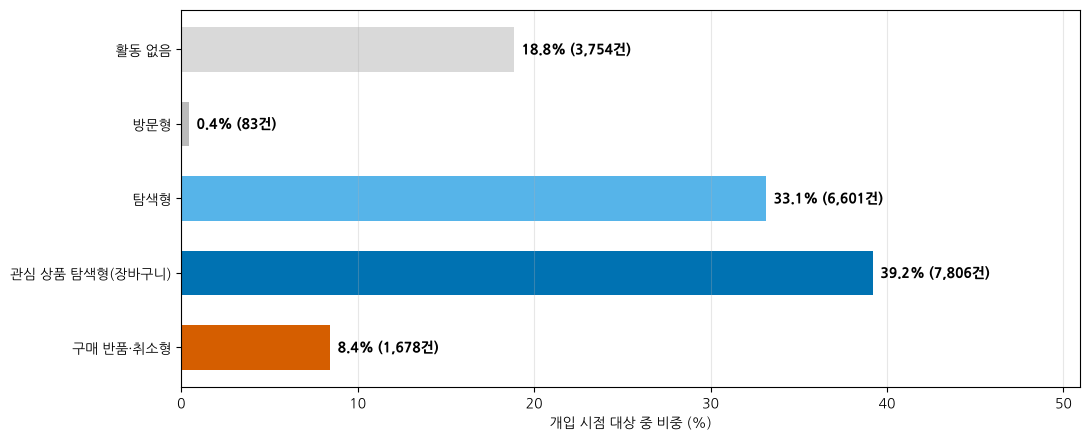

In [24]:
TYPE_ORDER = ['활동 없음', '방문형', '탐색형', '관심 상품 탐색형(장바구니)', '구매 반품·취소형']
TYPE_COLOR = {'활동 없음': COLOR_BASELINE, '방문형': '#BBBBBB', '탐색형': '#56B4E9',
              '관심 상품 탐색형(장바구니)': COLOR_RETAINED, '구매 반품·취소형': COLOR_AT_RISK}

# 세션 깊이: 1 방문 / 2 탐색 / 3 장바구니 / 4 구매 → 건별 가장 깊은 세션
flags = session_flags.reset_index()
flags['depth'] = np.select([flags['purchase'], flags['cart'], flags['explore']], [4, 3, 2], 1)
DEPTH_TYPE = {1: '방문형', 2: '탐색형', 3: '관심 상품 탐색형(장바구니)', 4: '구매 반품·취소형'}
trigger['interest_type'] = trigger['row_key'].map(flags.groupby('row_key')['depth'].max().map(DEPTH_TYPE)).fillna('활동 없음')

type_counts = trigger['interest_type'].value_counts().reindex(TYPE_ORDER, fill_value=0)
type_share = type_counts / type_counts.sum() * 100

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(TYPE_ORDER, type_share.values, color=[TYPE_COLOR[t] for t in TYPE_ORDER], height=0.6)
for y, (share, n) in enumerate(zip(type_share.values, type_counts.values)):
    ax.text(share, y, f'  {share:.1f}% ({n:,}건)', va='center', fontsize=10, weight='bold')
ax.invert_yaxis()
ax.set_xlim(0, type_share.max() * 1.3)

# 시각화 제목: 개입 시점 대상 고객의 관심 신호 유형 (마지막 구매 후 0~45일 기준)
plt.title('', fontsize=14, weight='bold')
plt.xlabel('개입 시점 대상 중 비중 (%)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 1.4. 결론

- **개입 단계**: 강등 고객의 접점은 `VIP` 구간에 남고 `Loyal` 구간에서 거의 사라지므로, 1·2차는 강등 전 `VIP` 단계에서 보냅니다.
- **개입 시점**: 1차는 마지막 구매 후 45일, 2차는 강등 판정 월 초, 할인이 들어가는 3차는 판정 후 약 1개월
- **유형별 메시지**: 1차는 관심 신호 유형에 따라 내용과 채널을 나눕니다.

### 1.4.1. VIP·Loyal 구간 주별 플랫폼 활동 비율

1-6·1-7을 마지막 구매 후 경과일 하나의 축으로 이어 붙입니다. 세로선(90일)을 넘으면 `Loyal`로 강등됩니다.

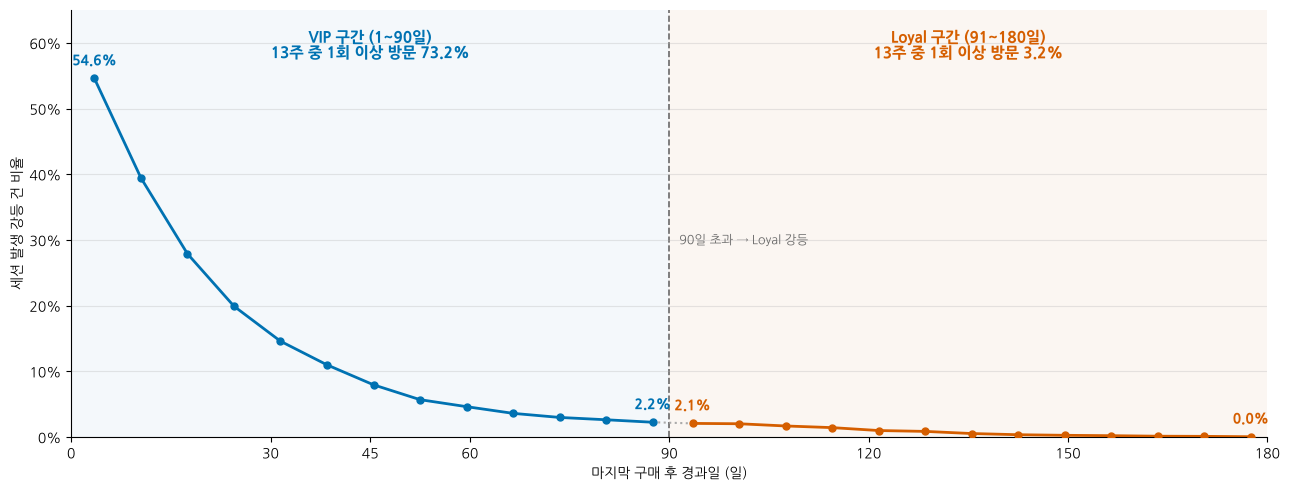

In [25]:
weeks = np.arange(1, N_WEEKS + 1)
vip_x = weeks * 7 - 3.5                  # 주차 중앙의 경과일 (1주차 = 1~7일)
loyal_x = VIP_END + weeks * 7 - 3.5      # 1주차 = 91~97일

fig, ax = plt.subplots(figsize=(13, 5))
ax.axvspan(0, VIP_END, color='#F4F8FB', zorder=0)
ax.axvspan(VIP_END, LOYAL_END, color='#FBF6F2', zorder=0)
ax.axvline(VIP_END, color='dimgray', linestyle='--', linewidth=1.2, zorder=1)

ax.plot(vip_x, vip_weekly.values, color=COLOR_RETAINED, marker='o', markersize=5, linewidth=2, zorder=3, label='VIP 구간')
ax.plot(loyal_x, loyal_weekly.values, color=COLOR_AT_RISK, marker='o', markersize=5, linewidth=2, zorder=3, label='Loyal 구간')
ax.plot([vip_x[-1], loyal_x[0]], [vip_weekly.iloc[-1], loyal_weekly.iloc[0]], color='#AAAAAA', linestyle=':', linewidth=1.5, zorder=2)

for x, y, color, va in [(vip_x[0], vip_weekly.iloc[0], COLOR_RETAINED, 'bottom'),
                        (vip_x[-1], vip_weekly.iloc[-1], COLOR_RETAINED, 'bottom'),
                        (loyal_x[0], loyal_weekly.iloc[0], COLOR_AT_RISK, 'bottom'),
                        (loyal_x[-1], loyal_weekly.iloc[-1], COLOR_AT_RISK, 'bottom')]:
    ax.annotate(f'{y:.1f}%', (x, y), xytext=(0, 8), textcoords='offset points', ha='center', va=va,
                fontsize=10, weight='bold', color=color)

y_top = 62
ax.text(VIP_END / 2, y_top, f'VIP 구간 (1~90일)\n13주 중 1회 이상 방문 {vip_any:.1f}%',
        ha='center', va='top', fontsize=11, weight='bold', color=COLOR_RETAINED)
ax.text((VIP_END + LOYAL_END) / 2, y_top, f'Loyal 구간 (91~180일)\n13주 중 1회 이상 방문 {loyal_any:.1f}%',
        ha='center', va='top', fontsize=11, weight='bold', color=COLOR_AT_RISK)
ax.text(VIP_END + 1.5, 30, '90일 초과 → Loyal 강등', fontsize=9, color='dimgray', va='center')

ax.set_xlim(0, LOYAL_END)
ax.set_ylim(0, 65)
ax.set_xticks([0, 30, 45, 60, 90, 120, 150, 180])
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
for side in ('right', 'top'):
    ax.spines[side].set_visible(False)

# 시각화 제목: VIP 강등 고객의 마지막 구매 후 주별 플랫폼 활동 비율 (VIP 구간 → Loyal 구간)
plt.title('', fontsize=14, weight='bold')
plt.xlabel('마지막 구매 후 경과일 (일)')
plt.ylabel('세션 발생 강등 건 비율')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.4.2. 개입 기준선 비교

2-5를 결론용으로 단순화합니다. 음영은 기준선 후보 구간(45~60일), 점선은 1차 개입 시점(45일)입니다.

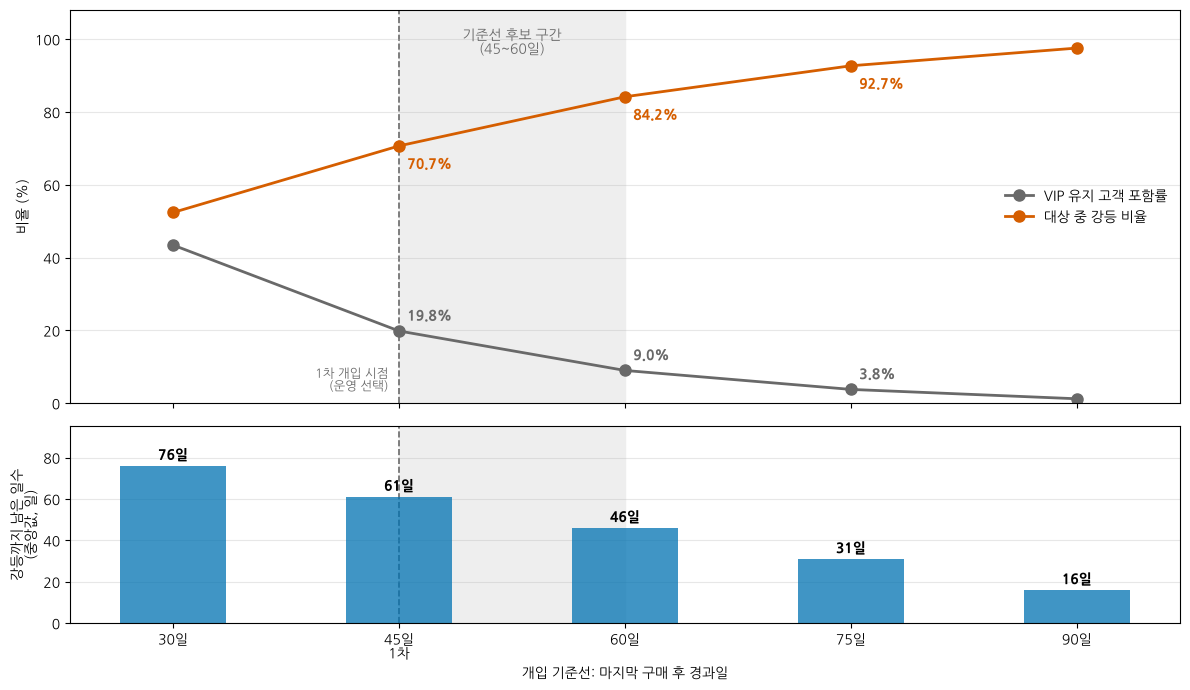

In [26]:
STEP_LABEL = {45: '\n1차'}
rule_plot = rule_eval.set_index('기준선(일)')

fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for ax in (ax_top, ax_bottom):
    ax.axvspan(45, 60, color='#EEEEEE', zorder=0)
    ax.axvline(45, color='dimgray', linestyle='--', linewidth=1.2, zorder=1)
    ax.grid(axis='y', alpha=0.3)

# 위: 비율 지표
ax_top.plot(rule_plot.index, rule_plot['VIP 유지 고객 포함률(%)'], marker='o', markersize=8, linewidth=2, color='dimgray', label='VIP 유지 고객 포함률')
ax_top.plot(rule_plot.index, rule_plot['대상 중 강등 비율(%)'], marker='o', markersize=8, linewidth=2, color=COLOR_AT_RISK, label='대상 중 강등 비율')
for t in (45, 60, 75):
    ax_top.annotate(f"{rule_plot.loc[t, 'VIP 유지 고객 포함률(%)']:.1f}%", (t, rule_plot.loc[t, 'VIP 유지 고객 포함률(%)']),
                    xytext=(6, 8), textcoords='offset points', ha='left', fontsize=10, color='dimgray', weight='bold')
    ax_top.annotate(f"{rule_plot.loc[t, '대상 중 강등 비율(%)']:.1f}%", (t, rule_plot.loc[t, '대상 중 강등 비율(%)']),
                    xytext=(6, -16), textcoords='offset points', ha='left', fontsize=10, color=COLOR_AT_RISK, weight='bold')
ax_top.text(52.5, 103, '기준선 후보 구간\n(45~60일)', ha='center', va='top', fontsize=10, color='dimgray')
ax_top.text(44.3, 3, '1차 개입 시점\n(운영 선택)', ha='right', va='bottom', fontsize=9, color='dimgray')
ax_top.set_ylim(0, 108)
ax_top.set_ylabel('비율 (%)')
ax_top.legend(loc='center right', frameon=False)

# 아래: 강등까지 남은 일수
bars = ax_bottom.bar(rule_plot.index, rule_plot['강등까지 남은 일수(중앙값)'], width=7, color=COLOR_RETAINED, alpha=0.75, zorder=2)
for t, v in rule_plot['강등까지 남은 일수(중앙값)'].items():
    ax_bottom.text(t, v + 2, f'{v:.0f}일', ha='center', va='bottom', fontsize=10, weight='bold')
ax_bottom.set_ylim(0, 95)
ax_bottom.set_ylabel('강등까지 남은 일수\n(중앙값, 일)')

ax_bottom.set_xticks(THRESHOLDS)
ax_bottom.set_xticklabels([f'{t}일{STEP_LABEL.get(t, "")}' for t in THRESHOLDS])

# 시각화 제목: 개입 기준선별 비용·위험·남은 시간 비교
ax_top.set_title('', fontsize=14, weight='bold')
ax_bottom.set_xlabel('개입 기준선: 마지막 구매 후 경과일')
plt.tight_layout()
plt.show()

### 1.4.3. 관심 신호 유형별 비중

3-4의 유형을 1차 채널 기준 네 유형으로 묶습니다. `방문형`은 보낼 상품 정보가 없어 `활동 없음`과 합칩니다.

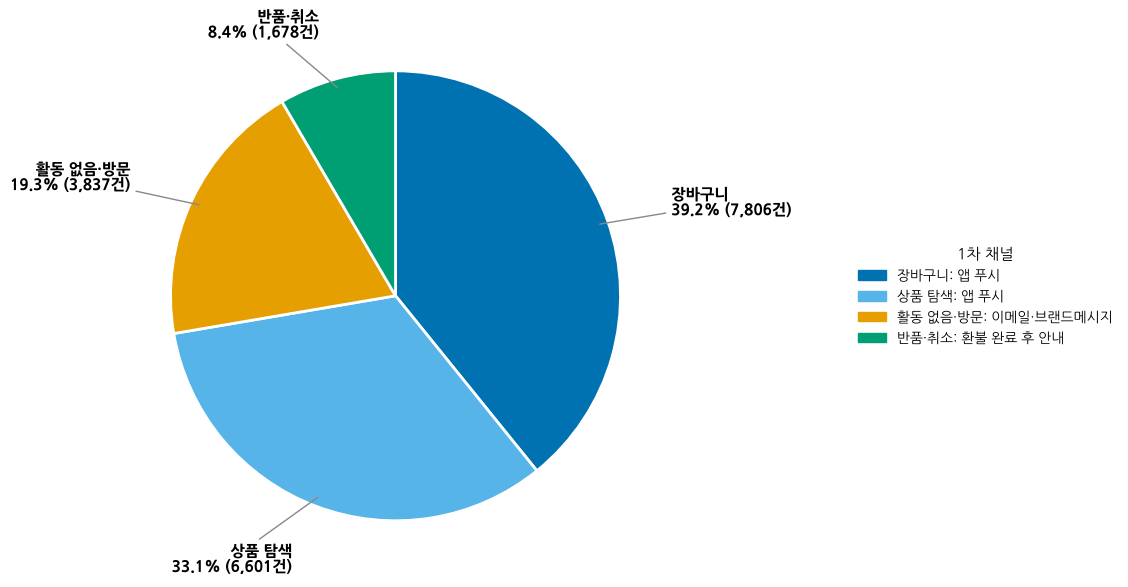

In [27]:
# 결론용 유형 묶음과 1차 채널 (실행안 표의 1차 행과 같은 구분)
SIGNAL_GROUP = {
    '관심 상품 탐색형(장바구니)': '장바구니',
    '탐색형': '상품 탐색',
    '활동 없음': '활동 없음·방문',
    '방문형': '활동 없음·방문',
    '구매 반품·취소형': '반품·취소',
}
SIGNAL_ORDER = ['장바구니', '상품 탐색', '활동 없음·방문', '반품·취소']
SIGNAL_CHANNEL = {'장바구니': '앱 푸시', '상품 탐색': '앱 푸시',
                  '활동 없음·방문': '이메일·브랜드메시지', '반품·취소': '환불 완료 후 안내'}
SIGNAL_COLOR = {'장바구니': COLOR_RETAINED, '상품 탐색': '#56B4E9',
                '활동 없음·방문': COLOR_LOW_VALUE, '반품·취소': COLOR_INTEREST}

signal_counts = trigger['interest_type'].map(SIGNAL_GROUP).value_counts().reindex(SIGNAL_ORDER)
signal_share = signal_counts / signal_counts.sum() * 100

fig, ax = plt.subplots(figsize=(12, 6))
wedges, _ = ax.pie(
    signal_counts.values, colors=[SIGNAL_COLOR[s] for s in SIGNAL_ORDER],
    startangle=90, counterclock=False, wedgeprops={'edgecolor': 'white', 'linewidth': 2},
)
for w, s in zip(wedges, SIGNAL_ORDER):
    angle = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(angle), np.sin(angle)
    ax.annotate(f'{s}\n{signal_share[s]:.1f}% ({signal_counts[s]:,}건)', xy=(0.95 * x, 0.95 * y), xytext=(1.3 * x, 1.25 * y),
                ha='left' if x >= 0 else 'right', va='center', fontsize=11, weight='bold',
                arrowprops=dict(arrowstyle='-', color='#888888', linewidth=1))
handles = [plt.Rectangle((0, 0), 1, 1, color=SIGNAL_COLOR[s]) for s in SIGNAL_ORDER]
ax.legend(handles, [f'{s}: {SIGNAL_CHANNEL[s]}' for s in SIGNAL_ORDER], title='1차 채널',
          loc='center left', bbox_to_anchor=(1.3, 0.5), ncol=1, frameon=False, fontsize=10, title_fontsize=11)
ax.set_aspect('equal')

# 시각화 제목: 45일 시점 개입 대상의 관심 신호 유형별 비중 (마지막 구매 후 0~45일 기준)
plt.title('', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

# 2. A/B 테스트 설계

1장의 개입 단계·시점·유형은 모두 개입이 없던 과거 데이터에서 도출했으므로, 개입의 효과 크기는 과거 데이터로 알 수 없고 실험으로 확인해야 합니다. 이 장은 실험 설계의 결정을 순서대로 데이터로 내립니다.

`1. 실험 질문과 구성` → `2. 대상과 배정 단위` → `3. 성과 지표` → `4. 표본과 MDE` → `5. 실험 일정` → `6. 설계 결과 요약`

- **설계 파라미터**: 데이터에서 나오지 않는 정의(α·검정력·선택 규칙)와 가정(모집 인원 집계·동의율)은 아래 셀에만 둡니다.

In [28]:
# 설계 파라미터: 정의(α·검정력·선택 규칙)와 가정(모집 인원·동의율). 값을 바꾸면 이후 MDE 표가 다시 계산됩니다.
ALPHA = 0.05                      # 유의수준 (양측)
POWER = 0.8                       # 검정력
MDE_STOP = 10                     # 한 달 추가 시 MDE 감소율(%)이 이 값 미만이 되는 첫 달에서 모집 종료 (운영 기준)
RECRUIT_MONTHS = range(3, 9)      # 검토할 모집 기간(개월)
RECRUIT_YEAR = 2024               # 모집 인원은 이 해에 시작했다고 보고 계산 (최근 규모가 유지된다는 가정)
RECRUIT_AGG = 'mean'              # 모집 인원 집계: 'mean' 시작 월 평균 / 'min' 가장 적게 모이는 시작 월 (보수적)
CONSENT_RATE = 0.5                # 광고 수신 동의율 (실험 2). 도입 시 회원 DB 값으로 교체
CONSENT_SCENARIOS = [0.3, 0.5, 0.7]   # 동의율 민감도 (2-2)

## 2.1. 실험 질문과 구성

| 개입 | 시점 | 1장 근거 | 실험에서 확인할 것 | 실험 |
|---|---|---|---|---|
| 1차: 관심 신호 유형별 콘텐츠 (무할인) | 마지막 구매 후 45일 | 2-3·2-5 (기준선), 3-4 (유형), 4-1 (VIP 구간의 접점) | 판정 시점 강등률이 낮아지는가 | 실험 1 |
| 2차: 등급 하락 예고 (무할인) | 강등 판정 월 초 | 2-3 (월말 경과일 60일 이후 다음 달 강등) | (1차와 함께) | 실험 1 |
| 3차: `VIP` 복귀 혜택 (할인) | 판정 다음 월말 | 2-6 (자연 재구매가 끝나는 시점), 4-1 (Loyal 구간의 접점) | `Loyal` 구간 재구매율이 높아지는가 | 실험 2 |

- **실험을 둘로 나누는 이유**: 1·2차와 3차는 대상(강등 전 `VIP` / 강등된 고객), 개입 시점, 결과가 나오는 시점이 달라 하나의 주 지표로 묶을 수 없습니다.
- **1·2차를 한 실험으로 묶는 이유**: 2차는 1차 대상 중 판정 월 초까지 구매가 없는 고객에게만 가는 후속 메시지라 대상과 주 지표(판정 시점 강등)가 같습니다. 1차와 2차의 개별 효과 분리는 이 실험의 범위 밖입니다.

## 2.2. 대상과 배정 단위

### 2.2.1. 실험 1 대상 흐름

- **재진입**: 같은 고객이 재구매 후 다시 45일에 도달하는 빈도와 간격 → 배정 단위(구매 건 / 고객)를 정합니다. 재진입이 있으면 건 단위 배정은 같은 고객을 두 그룹에 넣으므로 고객 단위로 처음 대상이 될 때 한 번만 배정하고, 재진입 시 그룹을 유지합니다.
- **2차 노출**: 대상 중 2차 시점(판정 월 초)까지 구매가 없어 2차를 받는 비율 → 실험 1이 측정하는 처치의 구성(1차만 / 1·2차)을 정합니다.

In [29]:
# 실험 1 대상: 1장 3-1의 trigger(구매 건)
exp1 = trigger[['row_key', 'user_id', 'last_order_dt', 'outcome']].merge(
    episodes[['row_key', 'check_month', 'days_to_check', 'days_to_next']], on='row_key'
)
exp1['trigger_dt'] = exp1['last_order_dt'] + pd.Timedelta(days=TRIGGER_DAY)
exp1['trigger_month'] = exp1['trigger_dt'].dt.to_period('M')
exp1['demoted'] = exp1['outcome'].eq('강등')

# 재진입: 고객별 대상 횟수와 연속된 대상 사이 간격
exp1 = exp1.sort_values(['user_id', 'trigger_dt']).reset_index(drop=True)
times_per_user = exp1.groupby('user_id').size()
reentry_gap = exp1.groupby('user_id')['trigger_dt'].diff().dt.days.dropna()

# 2차 노출: 2차 시점(판정 월 초)까지 유효 구매가 없는 건
exp1['days_to_2nd'] = (exp1['check_month'].dt.to_timestamp() - exp1['last_order_dt']).dt.total_seconds() / 86400
exp1['exposed_2nd'] = exp1['days_to_next'].isna() | exp1['days_to_next'].gt(exp1['days_to_2nd'])
exp1_first = exp1.drop_duplicates('user_id')   # 고객별 첫 대상 건 (배정 단위)

exp1_flow = pd.Series({
    '대상 구매 건(건)': len(exp1),
    '대상 고객(명)': exp1['user_id'].nunique(),
    '1회만 대상이 된 고객 비율(%)': round(times_per_user.eq(1).mean() * 100, 1),
    '2회 이상 대상이 된 고객 비율(%)': round(times_per_user.ge(2).mean() * 100, 1),
    '재진입 간격 중앙값(일)': round(reentry_gap.median()),
    '2차 시점(마지막 구매 후 경과일) 최소~최대': f"{exp1['days_to_2nd'].min():.0f} ~ {exp1['days_to_2nd'].max():.0f}",
    '2차 노출 비율(%, 고객별 첫 대상)': round(exp1_first['exposed_2nd'].mean() * 100, 1),
    '  └ 판정 시점 강등 고객 중(%)': round(exp1_first.loc[exp1_first['demoted'], 'exposed_2nd'].mean() * 100, 1),
    '  └ 판정 전 재구매 고객 중(%)': round(exp1_first.loc[~exp1_first['demoted'], 'exposed_2nd'].mean() * 100, 1),
}).to_frame('값')
exp1_flow

,값
대상 구매 건(건),19922
대상 고객(명),14807
1회만 대상이 된 고객 비율(%),73.3
2회 이상 대상이 된 고객 비율(%),26.7
재진입 간격 중앙값(일),86
2차 시점(마지막 구매 후 경과일) 최소~최대,60 ~ 91
"2차 노출 비율(%, 고객별 첫 대상)",75.6
└ 판정 시점 강등 고객 중(%),100.0
└ 판정 전 재구매 고객 중(%),19.9


### 2.2.2. 실험 2 대상 흐름과 실험 1과의 중첩

- **유입**: 3차 대상(1장 2-6)의 월별 건수 → 표본(4-3)의 입력입니다.
- **중첩**: 3차 대상 중 앞서 실험 1 대상(45일 트리거)이었던 비율 → 비율이 높으면 실험 2의 결과가 실험 1 배정의 영향을 받으므로, 실험 1 그룹별로 층화해 배정합니다.
- **시차**: 트리거(45일)부터 3차 시점까지 걸리는 일수 → 일정(5절)의 입력입니다.

In [30]:
# 3차 대상 월 유입: 3차 시점까지 재구매가 없는 강등 건 (180일 관측 조건 없이 3차 시점이 2024-12 이내)
third_pool = episodes.loc[
    episodes['outcome'].eq('강등')
    & (episodes['days_to_next'].isna() | episodes['days_to_next'].gt(episodes['days_to_check']))
].copy()
third_pool['days_to_third'] = (
    (third_pool['check_month'] + 2).dt.to_timestamp() - (third_pool['check_month'] + 1).dt.to_timestamp()
).dt.days
third_pool = third_pool.loc[~(third_pool['days_to_next'] - third_pool['days_to_check']).le(third_pool['days_to_third'])]
third_pool['third_month'] = third_pool['check_month'] + 1
exp2_monthly = third_pool.loc[third_pool['third_month'].dt.year.eq(RECRUIT_YEAR)].groupby('third_month').size()
EXP2_MONTHLY_ALL = exp2_monthly.agg(RECRUIT_AGG)     # 동의율 적용 전 월 대상
EXP2_MONTHLY = EXP2_MONTHLY_ALL * CONSENT_RATE

# 중첩과 시차
EXP2_OVERLAP = third_pool['row_key'].isin(exp1['row_key']).mean()
lag_to_third = third_pool['days_to_check'] + third_pool['days_to_third'] - TRIGGER_DAY

exp2_flow = pd.Series({
    f'{RECRUIT_YEAR}년 월 3차 대상 최저(건)': exp2_monthly.min(),
    f'{RECRUIT_YEAR}년 월 3차 대상 평균(건)': round(exp2_monthly.mean(), 1),
    f'{RECRUIT_YEAR}년 월 3차 대상 최고(건)': exp2_monthly.max(),
    f'월 배정 가능 인원(명, {RECRUIT_AGG} × 동의율 {CONSENT_RATE:.0%})': round(EXP2_MONTHLY, 1),
    '3차 대상 고객 수 ÷ 건수(%)': round(third_pool['user_id'].nunique() / len(third_pool) * 100, 1),
    '3차 대상 중 실험 1 대상이었던 비율(%)': round(EXP2_OVERLAP * 100, 1),
    '트리거 → 3차 시점 일수 (최소 / 중앙값 / 최대)': f"{lag_to_third.min():.0f} / {lag_to_third.median():.0f} / {lag_to_third.max():.0f}",
}).to_frame('값')
exp2_flow

,값
2024년 월 3차 대상 최저(건),601
2024년 월 3차 대상 평균(건),757.8
2024년 월 3차 대상 최고(건),835
"월 배정 가능 인원(명, mean × 동의율 50%)",378.9
3차 대상 고객 수 ÷ 건수(%),99.7
3차 대상 중 실험 1 대상이었던 비율(%),95.8
트리거 → 3차 시점 일수 (최소 / 중앙값 / 최대),75 / 91 / 108


## 2.3. 성과 지표

### 2.3.1. 주 지표와 기준값

- **실험 1 주 지표**: 판정 시점 강등률 = 판정 월말 스냅샷에서 `VIP`가 아닌 고객 ÷ 배정 고객
- **실험 2 주 지표**: 180일 도달 전 재구매율 = 3차 이후 `Loyal` 구간(마지막 구매 후 180일 이내)에 재구매한 고객 ÷ 배정 고객
- **판단 기준**
    - 월별 강등률의 표준편차가 표본 크기로 생기는 우연 변동과 비슷하면 기준값은 안정적이고, 그 폭이 MDE(4절)와 비교할 만하면 과거 값과 비교할 수 없어 동시 대조군이 필요합니다.
    - 그룹당 기대 사건 수가 한 자릿수면 정규 근사 대신 Fisher 정확 검정을 씁니다.
- 판정 월이 관측 기간을 넘는 마지막 트리거 월(2024-11)과, 180일까지 관측할 수 없는 판정 월(2024-07 이후)은 기준값에서 제외합니다.

In [31]:
# 실험 1: 고객별 첫 대상 건의 판정 시점 강등률과 월별 안정성
FULL_END = pd.Period('2024-10', 'M')   # 판정 월이 관측 기간 안에 모두 들어오는 마지막 트리거 월
EXP1_BASELINE_HIST = exp1_first['demoted'].mean()
exp1_monthly = (
    exp1_first.loc[exp1_first['trigger_month'].le(FULL_END)]
    .groupby('trigger_month')['demoted'].agg(['mean', 'size'])
)
expected_sd = np.sqrt(EXP1_BASELINE_HIST * (1 - EXP1_BASELINE_HIST) / exp1_monthly['size']).mean() * 100
EXP1_FOLLOW_DAYS = int(np.ceil((exp1['days_to_check'] - TRIGGER_DAY).max()))

# 실험 2: 3차 대상(1장 2-6)의 180일 도달 전 재구매율과 사건 수
EXP2_BASELINE = third_target['repurchased_loyal'].mean()
EXP2_FOLLOW_DAYS = int(np.ceil(third_remaining.max()))

primary_metric = pd.DataFrame({
    '실험 1: 판정 시점 강등률': {
        '산정 대상': f"고객별 첫 대상 {len(exp1_first):,}명",
        '기준값(%)': f"{EXP1_BASELINE_HIST * 100:.2f}",
        '사건 수': f"{int(exp1_first['demoted'].sum()):,}",
        '월별 범위(%)': f"{exp1_monthly['mean'].min() * 100:.1f} ~ {exp1_monthly['mean'].max() * 100:.1f}",
        '월별 표준편차 / 우연 변동 기대치(%p)': f"{exp1_monthly['mean'].std() * 100:.2f} / {expected_sd:.2f}",
        '결과 관측까지 최대 일수': f"{EXP1_FOLLOW_DAYS} (트리거 → 판정)",
    },
    '실험 2: 180일 도달 전 재구매율': {
        '산정 대상': f"3차 대상 {len(third_target):,}건 ({third_target['user_id'].nunique():,}명)",
        '기준값(%)': f"{EXP2_BASELINE * 100:.2f}",
        '사건 수': f"{int(third_target['repurchased_loyal'].sum()):,}",
        '월별 범위(%)': '사건 수가 적어 월별 비교 생략',
        '월별 표준편차 / 우연 변동 기대치(%p)': '-',
        '결과 관측까지 최대 일수': f"{EXP2_FOLLOW_DAYS} (3차 → 180일)",
    },
})
primary_metric

,실험 1: 판정 시점 강등률,실험 2: 180일 도달 전 재구매율
산정 대상,"고객별 첫 대상 14,807명","3차 대상 9,790건 (9,769명)"
기준값(%),69.58,0.45
사건 수,"10,303",44
월별 범위(%),66.9 ~ 72.8,사건 수가 적어 월별 비교 생략
월별 표준편차 / 우연 변동 기대치(%p),1.49 / 1.78,-
결과 관측까지 최대 일수,77 (트리거 → 판정),60 (3차 → 180일)


### 2.3.2. 효과의 지속성

주 지표가 개선되어도 효과가 오래가지 않으면 매출로 이어지지 않습니다. 과거 데이터에서 다음 두 가지를 확인해 보조 지표를 정합니다.

- **실험 1**: 45일 이후 재구매로 강등을 피한 구매 건이 **다음 구매 주기에서** 강등되는 비율을, 45일 이전에 재구매한 건과 비교합니다. 강등을 피한 고객이 곧 다시 강등된다면 판정 시점 지표만으로는 부족하고, 더 긴 기간의 지표(6개월 후 `VIP` 비율·누적 매출총이익)가 필요합니다.
- **실험 2**: `Loyal` 구간에서 재구매한 강등 고객이 `VIP`로 복귀하는 비율. 재구매가 곧 복귀라면 `VIP` 복귀율은 주 지표와 같은 정보이므로 보조 지표로 따로 두지 않습니다.

In [32]:
# 실험 1: 같은 고객의 다음 구매 건(다음 VIP 마지막 구매일)이 강등으로 끝나는 비율
ep_seq = episodes.sort_values(['user_id', 'last_order_dt']).copy()
ep_seq['next_outcome'] = ep_seq.groupby('user_id')['outcome'].shift(-1)
ep_seq['group'] = np.select(
    [~ep_seq['row_key'].isin(exp1['row_key']), ep_seq['outcome'].eq('강등')],
    ['45일 이전 재구매', '강등'],
    default='45일 ~ 판정 재구매 (강등 회피)',
)
has_next = ep_seq['next_outcome'].notna()
rows = []
for g in ['45일 이전 재구매', '45일 ~ 판정 재구매 (강등 회피)', '강등']:
    s = ep_seq.loc[has_next & ep_seq['group'].eq(g), 'next_outcome']
    rows.append({'실험': '실험 1', '구분': g, '확인하는 비율': '다음 구매 주기에서 강등되는 비율',
                 '대상(건)': len(s), '비율(%)': s.eq('강등').mean() * 100})

# 실험 2: Loyal 구간 재구매 후 6개월 안에 VIP로 복귀한 건
repurchased = third_target.loc[third_target['repurchased_loyal']]
returned_vip = [
    any(segment_matrix.at[u, m + h] == 'VIP' for h in range(1, 7) if m + h <= last_snapshot)
    for u, m in zip(repurchased['user_id'], repurchased['check_month'])
]
rows.append({'실험': '실험 2', '구분': 'Loyal 구간 재구매', '확인하는 비율': '재구매 후 6개월 안에 VIP로 복귀한 비율',
             '대상(건)': len(repurchased), '비율(%)': np.mean(returned_vip) * 100})
persistence = pd.DataFrame(rows).set_index(['실험', '구분'])
persistence.round(1)

확인하는 비율  대상(건)  비율(%)
실험   구분                                                          
실험 1 45일 이전 재구매                  다음 구매 주기에서 강등되는 비율  23407   34.4
     45일 ~ 판정 재구매 (강등 회피)        다음 구매 주기에서 강등되는 비율   5281   30.7
     강등                          다음 구매 주기에서 강등되는 비율    253   37.2
실험 2 Loyal 구간 재구매          재구매 후 6개월 안에 VIP로 복귀한 비율     44  100.0

### 2.3.3. 매출총이익 보조 지표의 분포

주 지표 개선이 이익으로 이어지는지 확인하는 보조 지표의 평균과 표준편차입니다. 표준편차는 4-6에서 실험 표본으로 차이를 판단할 수 있는지 보는 데 씁니다.

- **실험 1**: 배정 고객당 매출총이익. ① 트리거 → 판정 월말, ② 트리거 후 6개월 (6개월을 관측할 수 있는 고객만)
- **실험 2**: 배정 고객당 매출총이익, 3차 시점 → 마지막 구매 후 180일 (할인 전)
- **비교**: 판정 시점 강등 고객과 아닌 고객의 차이 → 강등 1건을 막았을 때 늘어나는 매출총이익

In [33]:
def gp_between(targets, start_col, end_col, key):
    # 대상(key)별 (start, end] 기간의 매출총이익 합계. 구매가 없으면 0
    cols = list(dict.fromkeys([key, 'user_id', start_col, end_col]))
    m = oi_items[['user_id', 'created_at', 'gross_profit']].merge(targets[cols], on='user_id')
    m = m.loc[m['created_at'].gt(m[start_col]) & m['created_at'].le(m[end_col])]
    return targets[key].map(m.groupby(key)['gross_profit'].sum()).fillna(0)

# 실험 1: 고객별 첫 대상 건 기준
gp1 = exp1_first[['user_id', 'trigger_dt', 'check_month', 'demoted']].copy()
gp1['check_end'] = (gp1['check_month'] + 1).dt.to_timestamp()
gp1['h6_end'] = gp1['trigger_dt'] + pd.Timedelta(days=182)
gp1['gp_to_check'] = gp_between(gp1, 'trigger_dt', 'check_end', key='user_id')
gp1['gp_6m'] = gp_between(gp1, 'trigger_dt', 'h6_end', key='user_id')
gp1_6m = gp1.loc[gp1['h6_end'].le(pd.Timestamp('2025-01-01'))]

# 실험 2: 3차 대상 건 기준 (할인 전)
gp2 = third_target[['row_key', 'user_id', 'last_order_dt', 'days_to_check', 'days_to_third', 'repurchased_loyal']].copy()
gp2['third_dt'] = gp2['last_order_dt'] + pd.to_timedelta(gp2['days_to_check'] + gp2['days_to_third'], unit='D')
gp2['end_180'] = gp2['last_order_dt'] + pd.Timedelta(days=LOYAL_END_DAY)
gp2['gp'] = gp_between(gp2, 'third_dt', 'end_180', key='row_key')

def gp_row(values, flag, n_label):
    return {'대상': n_label, '평균(원)': values.mean(), '표준편차(원)': values.std(),
            '사건 발생 고객 평균(원)': values[flag].mean(), '사건 미발생 고객 평균(원)': values[~flag].mean()}

gp_dist = pd.DataFrame({
    '실험 1 ① 트리거 → 판정 월말': gp_row(gp1['gp_to_check'], ~gp1['demoted'], f"{len(gp1):,}명"),
    '실험 1 ② 트리거 후 6개월': gp_row(gp1_6m['gp_6m'], ~gp1_6m['demoted'], f"{len(gp1_6m):,}명"),
    '실험 2 3차 → 180일 (할인 전)': gp_row(gp2['gp'], gp2['repurchased_loyal'], f"{len(gp2):,}건"),
}).T
gp_dist = gp_dist.rename(columns={'사건 발생 고객 평균(원)': '강등 회피·재구매 고객 평균(원)', '사건 미발생 고객 평균(원)': '강등·미재구매 고객 평균(원)'})
num_cols = gp_dist.columns.drop('대상')
gp_dist[num_cols] = gp_dist[num_cols].astype(float).round(0)
gp_dist

,대상,평균(원),표준편차(원),강등 회피·재구매 고객 평균(원),강등·미재구매 고객 평균(원)
실험 1 ① 트리거 → 판정 월말,"14,807명",66015.0,134786.0,217016.0,4.0
실험 1 ② 트리거 후 6개월,"11,636명",121496.0,240663.0,379732.0,8168.0
실험 2 3차 → 180일 (할인 전),"9,790건",1040.0,20129.0,231333.0,0.0


### 2.3.4. 가드레일

실험이 고객 관계를 해치는지 보는 지표(광고 수신 거부율·앱 푸시 해제율)는 해당 로그가 없어 기준값을 산출할 수 없습니다. 실험 시작 전 운영 데이터의 평소 수준으로 중단 기준을 숫자로 정합니다.

## 2.4. 표본과 MDE

### 2.4.1. 실험 1 모집 기간별 표본과 MDE

모집 기간을 정하기 위해 기간별 표본과 MDE를 비교합니다. 실험 기간에 들어오는 고객에는 예전에 대상이 된 적이 있는 고객도 섞이므로, p₀와 n을 모두 **모집 기간 안에서 처음 대상이 된 고객** 기준으로 계산합니다.

- **모집 창**: `RECRUIT_YEAR`의 각 달에서 시작하는 k개월 (모집 종료가 `FULL_END`를 넘지 않는 시작 월만)
- **n**: 창 안에서 처음 대상이 된 고유 고객 수 (시작 월 간 `RECRUIT_AGG`)
- **p₀**: 같은 고객들의 판정 시점 강등률
- **MDE**: 두 비율 z검정(양측)에서 검정력 80%를 만족하는 최소 강등률 감소 폭 (계산 과정은 4-2에서 검증)

In [34]:
from scipy.optimize import brentq
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

analysis = NormalIndPower()

def power_two_prop(p_control, p_treatment, n_control, n_treatment):
    # 두 비율 z검정(양측)의 검정력
    effect_size = proportion_effectsize(p_control, p_treatment)
    return analysis.power(effect_size=effect_size, nobs1=n_control, alpha=ALPHA,
                          ratio=n_treatment / n_control, alternative='two-sided')

def mde_two_prop(p_control, n_control, n_treatment):
    # 검정력 목표를 만족하는 최소 감소 폭(비율). 실험 1은 강등률을 낮추는 방향입니다.
    return brentq(lambda delta: power_two_prop(p_control, p_control - delta, n_control, n_treatment) - POWER,
                  1e-8, p_control - 1e-8)

def pick_months(table):
    # 한 달 추가 시 감소율이 기준 미만이 되는 첫 모집 기간
    table['한 달 추가 시 감소율(%)'] = (1 - table['MDE(%p)'].shift(-1) / table['MDE(%p)']) * 100
    chosen = table.loc[table['한 달 추가 시 감소율(%)'].lt(MDE_STOP), '모집 기간(개월)'].iloc[0]
    table['선택'] = np.where(table['모집 기간(개월)'].eq(chosen), '✔', '')
    return table, chosen

rows = []
for k in RECRUIT_MONTHS:
    starts = pd.period_range(f'{RECRUIT_YEAR}-01', min(pd.Period(f'{RECRUIT_YEAR}-12', 'M'), FULL_END - (k - 1)), freq='M')
    windows = []
    for s in starts:
        # 모집 창 안에서 고객별 처음 대상이 된 건
        in_window = exp1.loc[exp1['trigger_month'].between(s, s + (k - 1))]
        first_in = in_window.sort_values('last_order_dt').drop_duplicates('user_id')
        windows.append({'size': len(first_in), 'sum': first_in['demoted'].sum(),
                        'reentry': in_window.groupby('user_id').size().ge(2).mean()})
    windows = pd.DataFrame(windows)
    n_total = int(windows['size'].agg(RECRUIT_AGG))
    n_control = n_total // 2
    n_treatment = n_total - n_control
    p_control = windows['sum'].sum() / windows['size'].sum()
    rows.append({
        '모집 기간(개월)': k,
        '시작 월 수': len(starts),
        '배정 고객 수 평균(명)': windows['size'].mean(),
        '배정 고객 수 최소(명)': windows['size'].min(),
        '배정 고객 수(명)': n_total,
        '창 안 재진입 고객 비율(%)': windows['reentry'].mean() * 100,
        '그룹당 고객 수(명)': n_control,
        '기준값(%)': p_control * 100,
        'MDE(%p)': -mde_two_prop(p_control, n_control, n_treatment) * 100,
    })
exp1_mde, EXP1_MONTHS = pick_months(pd.DataFrame(rows))
exp1_mde.round(2)

,모집 기간(개월),시작 월 수,배정 고객 수 평균(명),배정 고객 수 최소(명),배정 고객 수(명),창 안 재진입 고객 비율(%),그룹당 고객 수(명),기준값(%),MDE(%p),한 달 추가 시 감소율(%),선택
0,3,8,3274.50,3058,3274,4.48,1637,70.10,-4.57,11.74,
1,4,7,4183.14,3918,4183,8.89,2091,70.14,-4.04,8.93,✔
2,5,6,5036.33,4751,5036,12.99,2518,70.05,-3.68,7.16,
3,6,5,5844.00,5639,5844,16.34,2922,69.92,-3.41,6.02,
4,7,4,6620.50,6455,6620,18.86,3310,69.79,-3.21,5.30,
5,8,3,7399.33,7312,7399,20.90,3699,69.57,-3.04,NaN,


### 2.4.2. 실험 1 MDE 계산과 검정력 검증

4-1에서 선택한 모집 기간의 설계 값으로 MDE를 계산하고, 그 MDE에서 검정력이 목표를 만족하는지 확인합니다.

- **n_total**: 모집 기간 동안 배정되는 고객 수 (연간 대상 수가 아님)
- **판단 기준**: MDE에서의 검정력이 목표와 같고, 목표로 둘 감소 폭에서의 검정력이 목표 이상이어야 합니다.

In [35]:
# 1. 실험 설계 조건 (4-1에서 선택한 모집 기간)
design = exp1_mde.set_index('모집 기간(개월)').loc[EXP1_MONTHS]
p_control = design['기준값(%)'] / 100
n_total = int(design['배정 고객 수(명)'])

alpha = ALPHA
power_target = POWER

# 2. 실험군과 대조군 배분 (50:50)
n_control = n_total // 2
n_treatment = n_total - n_control

# 3. 특정 강등률 감소 폭에서 검정력 계산
def calculate_power(delta):
    p_treatment = p_control - delta
    effect_size = proportion_effectsize(p_control, p_treatment)
    return analysis.power(
        effect_size=effect_size,
        nobs1=n_control,
        alpha=alpha,
        ratio=n_treatment / n_control,
        alternative='two-sided',
    )

# 4. 검정력 80%를 만족하는 최소 강등률 감소 폭 탐색
mde = brentq(lambda delta: calculate_power(delta) - power_target, 1e-8, p_control - 1e-8)

# 5. 검증: MDE와 목표 감소 폭에서의 검정력
TARGET_DELTA = 0.04   # 보고서 목표: 강등률 −4%p
print(f"모집 기간: {EXP1_MONTHS}개월 (배정 {n_total:,}명)")
print(f"대조군 강등률: {p_control:.2%}")
print(f"대조군 표본 수: {n_control:,}명")
print(f"실험군 표본 수: {n_treatment:,}명")
print(f"MDE: {mde * 100:.2f}%p")
print(f"탐지 가능한 실험군 강등률: {(p_control - mde) * 100:.2f}%")
print(f"MDE에서의 검정력: {calculate_power(mde):.1%}")
print(f"목표 감소 폭 {TARGET_DELTA * 100:.0f}%p에서의 검정력: {calculate_power(TARGET_DELTA):.1%}")

모집 기간: 4개월 (배정 4,183명)
대조군 강등률: 70.14%
대조군 표본 수: 2,091명
실험군 표본 수: 2,092명
MDE: 4.04%p
탐지 가능한 실험군 강등률: 66.11%
MDE에서의 검정력: 80.0%
목표 감소 폭 4%p에서의 검정력: 79.3%


### 2.4.3. 실험 2 모집 기간별 표본과 MDE

그룹당 기대 사건 수가 한 자릿수라(3-1) 정규 근사 대신 Fisher 정확 검정(양측)의 검정력을 이항분포로 직접 계산합니다.

- **n**: 모집 기간 × 월 배정 가능 인원(2-2)

In [36]:
from functools import lru_cache
from scipy.stats import binom, fisher_exact

@lru_cache(maxsize=None)
def fisher_reject(n_control, n_treatment, x_max_c, x_max_t):
    # 대조군 i건, 실험군 j건 재구매일 때 Fisher 정확 검정(양측)이 기각하는지 여부
    return np.array([[fisher_exact([[i, n_control - i], [j, n_treatment - j]])[1] < ALPHA
                      for j in range(x_max_t + 1)] for i in range(x_max_c + 1)])

def power_fisher(p_control, p_treatment, n_control, n_treatment):
    # 검정력 = Σ P(대조군 i건) × P(실험군 j건) × [기각 여부]
    x_max_c = int(binom.ppf(1 - 1e-12, n_control, p_control))
    x_max_t = int(binom.ppf(1 - 1e-12, n_treatment, min(p_control + 0.05, 1)))
    reject = fisher_reject(n_control, n_treatment, x_max_c, x_max_t)
    prob_c = binom.pmf(np.arange(x_max_c + 1), n_control, p_control)
    prob_t = binom.pmf(np.arange(x_max_t + 1), n_treatment, p_treatment)
    return prob_c @ reject @ prob_t

def mde_fisher(p_control, n_control, n_treatment, max_lift=0.05, tol=1e-6):
    # 검정력 목표를 처음 만족하는 최소 증가 폭(비율). Fisher 검정력은 계단형이라 brentq 대신 이분 탐색을 씁니다.
    lo, hi = 0.0, max_lift
    while hi - lo > tol:
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if power_fisher(p_control, p_control + mid, n_control, n_treatment) >= POWER else (mid, hi)
    return hi

rows = []
for k in RECRUIT_MONTHS:
    n_total = int(round(EXP2_MONTHLY * k))
    n_control = n_total // 2
    n_treatment = n_total - n_control
    rows.append({'모집 기간(개월)': k, '배정 고객 수(명)': n_total, '그룹당 고객 수(명)': n_control,
                 '기준값(%)': EXP2_BASELINE * 100, '그룹당 대조군 기대 재구매(건)': n_control * EXP2_BASELINE,
                 'MDE(%p)': mde_fisher(EXP2_BASELINE, n_control, n_treatment) * 100})
exp2_mde, EXP2_MONTHS = pick_months(pd.DataFrame(rows))
exp2_mde.round(2)

,모집 기간(개월),배정 고객 수(명),그룹당 고객 수(명),기준값(%),그룹당 대조군 기대 재구매(건),MDE(%p),한 달 추가 시 감소율(%),선택
0,3,1137,568,0.45,2.55,2.05,18.94,
1,4,1516,758,0.45,3.41,1.66,14.58,
2,5,1895,947,0.45,4.26,1.42,11.69,
3,6,2274,1137,0.45,5.11,1.26,10.08,
4,7,2652,1326,0.45,5.96,1.13,8.96,✔
5,8,3031,1515,0.45,6.81,1.03,NaN,


### 2.4.4. 실험 2 MDE 계산과 검정력 검증

4-3에서 선택한 모집 기간의 설계 값으로 MDE를 계산하고, 그 MDE에서 Fisher 정확 검정의 검정력이 목표를 만족하는지 확인합니다. 정규 근사 MDE에서의 실제(Fisher) 검정력도 함께 봅니다.

- **판단 기준**: 정규 근사 MDE에서의 Fisher 검정력이 목표보다 낮으면, 정규 근사로 설계했을 때 표본이 부족해지므로 Fisher 기준 MDE를 사용합니다.

In [37]:
# 1. 실험 설계 조건 (4-3에서 선택한 모집 기간)
design = exp2_mde.set_index('모집 기간(개월)').loc[EXP2_MONTHS]
p_control = design['기준값(%)'] / 100
n_total = int(design['배정 고객 수(명)'])

alpha = ALPHA
power_target = POWER

# 2. 실험군과 대조군 배분 (50:50)
n_control = n_total // 2
n_treatment = n_total - n_control

# 3. 특정 재구매율 증가 폭에서 검정력 계산 (Fisher 정확 검정)
def calculate_power(delta):
    return power_fisher(p_control, p_control + delta, n_control, n_treatment)

# 4. 검정력 80%를 만족하는 최소 재구매율 증가 폭 탐색
mde = mde_fisher(p_control, n_control, n_treatment)

# (비교) 정규 근사 MDE와, 그 값에서의 실제(Fisher) 검정력
mde_normal = brentq(lambda delta: power_two_prop(p_control, p_control + delta, n_control, n_treatment) - power_target,
                    1e-8, 1 - p_control - 1e-8)

# 5. 검증
print(f"모집 기간: {EXP2_MONTHS}개월 (배정 {n_total:,}명, 동의율 {CONSENT_RATE:.0%})")
print(f"대조군 재구매율: {p_control:.2%} (그룹당 기대 재구매 {n_control * p_control:.1f}건)")
print(f"대조군 표본 수: {n_control:,}명")
print(f"실험군 표본 수: {n_treatment:,}명")
print(f"MDE (Fisher): +{mde * 100:.2f}%p")
print(f"탐지 가능한 실험군 재구매율: {(p_control + mde) * 100:.2f}%")
print(f"MDE에서의 검정력: {calculate_power(mde):.1%}")
print(f"(비교) 정규 근사 MDE: +{mde_normal * 100:.2f}%p → 이 값에서 Fisher 검정력 {calculate_power(mde_normal):.1%}")

모집 기간: 7개월 (배정 2,652명, 동의율 50%)
대조군 재구매율: 0.45% (그룹당 기대 재구매 6.0건)
대조군 표본 수: 1,326명
실험군 표본 수: 1,326명
MDE (Fisher): +1.13%p
탐지 가능한 실험군 재구매율: 1.58%
MDE에서의 검정력: 80.0%
(비교) 정규 근사 MDE: +1.02%p → 이 값에서 Fisher 검정력 72.7%


### 2.4.5. 실험 2 표본의 민감도

실험 2의 n을 바꾸는 두 요인이 모집 기간을 얼마나 바꾸는지 확인합니다.

- **동의율**: 데이터가 없는 가정값(`CONSENT_SCENARIOS`)
- **실험 1의 효과**: 실험 1 실험군의 강등이 MDE만큼 줄면 3차 대상도 줄어듭니다. 3차 대상 중 실험 1 대상 비율(2-2)과 실험군 비율(50%)을 곱해 실험 기간 중 감소분을, 1·2차를 전면 도입한 뒤의 감소분과 함께 계산합니다.
- **표**: 4-3에서 정한 배정 고객 수를 모으는 데 필요한 모집 기간

In [38]:
target_n = int(round(EXP2_MONTHLY * EXP2_MONTHS))     # 4-3에서 정한 배정 고객 수
exp1_effect = abs(exp1_mde.set_index('모집 기간(개월)').loc[EXP1_MONTHS, 'MDE(%p)']) / 100
exp1_p0 = exp1_mde.set_index('모집 기간(개월)').loc[EXP1_MONTHS, '기준값(%)'] / 100
shrink = {
    '실험 1 효과 없음': 0.0,
    '실험 1 진행 중 (실험군 50%만 효과)': EXP2_OVERLAP * 0.5 * exp1_effect / exp1_p0,
    '1·2차 전면 도입 후': EXP2_OVERLAP * exp1_effect / exp1_p0,
}

rows = []
for c in CONSENT_SCENARIOS:
    for label, s in shrink.items():
        monthly = EXP2_MONTHLY_ALL * c * (1 - s)
        n_total = int(round(monthly * EXP2_MONTHS))
        rows.append({
            '동의율(%)': c * 100,
            '실험 1 효과 반영': label,
            '3차 대상 감소율(%)': s * 100,
            '월 배정 가능 인원(명)': monthly,
            f'{EXP2_MONTHS}개월 모집 시 MDE(%p)': mde_fisher(EXP2_BASELINE, n_total // 2, n_total - n_total // 2) * 100,
            f'배정 {target_n:,}명에 필요한 모집 기간(개월)': target_n / monthly,
        })
exp2_sensitivity = pd.DataFrame(rows)
exp2_sensitivity.round(2)

,동의율(%),실험 1 효과 반영,3차 대상 감소율(%),월 배정 가능 인원(명),7개월 모집 시 MDE(%p),"배정 2,652명에 필요한 모집 기간(개월)"
0,30.0,실험 1 효과 없음,0.00,227.35,1.61,11.66
1,30.0,실험 1 진행 중 (실험군 50%만 효과),2.76,221.08,1.64,12.00
2,30.0,1·2차 전면 도입 후,5.51,214.81,1.67,12.35
3,50.0,실험 1 효과 없음,0.00,378.92,1.13,7.00
4,50.0,실험 1 진행 중 (실험군 50%만 효과),2.76,368.47,1.15,7.20
5,50.0,1·2차 전면 도입 후,5.51,358.02,1.17,7.41
6,70.0,실험 1 효과 없음,0.00,530.48,0.89,5.00
7,70.0,실험 1 진행 중 (실험군 50%만 효과),2.76,515.86,0.91,5.14
8,70.0,1·2차 전면 도입 후,5.51,501.23,0.93,5.29


### 2.4.6. 보조 지표의 검출 가능성

매출총이익 보조 지표(3-3)의 차이를 선택한 표본으로 판단할 수 있는지 확인합니다.

- **기대 증분**: 주 지표가 MDE만큼 개선될 때 늘어나는 배정 고객당 매출총이익 = MDE × (강등 회피·재구매 고객 평균 − 강등·미재구매 고객 평균) (실험 2는 할인 전)
- **신뢰구간 반폭**: 두 그룹 평균 차이의 95% 신뢰구간 반폭 = 1.96 × 표준편차 × √(2 / 그룹당 n)
- **판단 기준**: 기대 증분이 반폭보다 충분히 크지 않으면, 보조 지표는 유의성이 아니라 차이의 방향과 신뢰구간으로 판단합니다.

In [39]:
n1 = int(exp1_mde.set_index('모집 기간(개월)').loc[EXP1_MONTHS, '그룹당 고객 수(명)'])
n2 = int(exp2_mde.set_index('모집 기간(개월)').loc[EXP2_MONTHS, '그룹당 고객 수(명)'])
mde1 = abs(exp1_mde.set_index('모집 기간(개월)').loc[EXP1_MONTHS, 'MDE(%p)']) / 100
mde2 = exp2_mde.set_index('모집 기간(개월)').loc[EXP2_MONTHS, 'MDE(%p)'] / 100

rows = []
for name, n, mde_value in [('실험 1 ① 트리거 → 판정 월말', n1, mde1), ('실험 1 ② 트리거 후 6개월', n1, mde1),
                           ('실험 2 3차 → 180일 (할인 전)', n2, mde2)]:
    d = gp_dist.loc[name]
    expected = mde_value * (d['강등 회피·재구매 고객 평균(원)'] - d['강등·미재구매 고객 평균(원)'])
    half_width = 1.96 * d['표준편차(원)'] * np.sqrt(2 / n)
    rows.append({'보조 지표': name, '그룹당 n(명)': n, '기대 증분(원)': expected,
                 '95% 신뢰구간 반폭(원)': half_width, '기대 증분 ÷ 반폭': expected / half_width})
secondary_power = pd.DataFrame(rows).set_index('보조 지표')
secondary_power.round(2)

,그룹당 n(명),기대 증분(원),95% 신뢰구간 반폭(원),기대 증분 ÷ 반폭
보조 지표,,,,
실험 1 ① 트리거 → 판정 월말,2091,8757.01,8170.32,1.07
실험 1 ② 트리거 후 6개월,2091,14993.60,14588.26,1.03
실험 2 3차 → 180일 (할인 전),1326,2612.45,1532.22,1.71


## 2.5. 실험 일정

실험 2의 대상은 실험 1 대상이 트리거 후 약 3개월이 지나야 생기므로, 두 실험의 기간을 더하는 것만으로는 전체 일정이 나오지 않습니다. 실험 1 시작을 0개월로 두고 각 시점을 계산합니다.

- **실험 2 시작**: 실험 1 시작 후 3차 대상이 처음 생기는 시점 (트리거 → 3차 시점 최소 일수, 2-2)
- **실험 2 표본 중 실험 1 배정 고객 비율**: 실험 2 모집 기간에 들어오는 3차 대상의 트리거 시점이 실험 1 모집 기간 안에 있는 비율. 트리거 → 3차 시점 일수 분포(2-2)를 쓰고, 모집 기간 동안 대상이 고르게 들어온다고 가정합니다. 실험 1 모집이 끝난 뒤 들어오는 대상은 실험 1 미배정 층으로 따로 층화합니다.

In [40]:
MONTH_DAYS = 30.4
exp2_start = lag_to_third.min() / MONTH_DAYS
exp2_end_recruit = exp2_start + EXP2_MONTHS

# 실험 2 모집 기간의 도착 시점(개월)을 고르게 두고, 각 3차 대상의 트리거 시점 = 도착 − 시차
arrival = np.linspace(exp2_start, exp2_end_recruit, 400)
trigger_time = arrival[:, None] - lag_to_third.values[None, :] / MONTH_DAYS
from_exp1 = ((trigger_time >= 0) & (trigger_time < EXP1_MONTHS)).mean()

schedule = pd.Series({
    '실험 1 모집 (개월)': f"0 ~ {EXP1_MONTHS}",
    '실험 1 결과 확정 (개월)': f"{EXP1_MONTHS + EXP1_FOLLOW_DAYS / MONTH_DAYS:.1f}",
    '실험 2 모집 (개월)': f"{exp2_start:.1f} ~ {exp2_end_recruit:.1f}",
    '실험 2 결과 확정 (개월)': f"{exp2_end_recruit + EXP2_FOLLOW_DAYS / MONTH_DAYS:.1f}",
    '실험 2 표본 중 실험 1 배정 고객 비율(%)': f"{from_exp1 * EXP2_OVERLAP * 100:.1f}",
}).to_frame('값')
schedule

,값
실험 1 모집 (개월),0 ~ 4
실험 1 결과 확정 (개월),6.5
실험 2 모집 (개월),2.5 ~ 9.5
실험 2 결과 확정 (개월),11.4
실험 2 표본 중 실험 1 배정 고객 비율(%),54.6


## 2.6. 설계 결과 요약

1~5절에서 정한 설계 값을 한 표로 정리합니다. 보고서와 3장(CRM 손익분기와 ROI)은 이 표의 값을 사용합니다.

In [41]:
def design_col(table, months, follow_days, unit, assignment, test):
    row = table.set_index('모집 기간(개월)').loc[months]
    return {
        '배정': assignment,
        '주 지표 기준값(%)': round(row['기준값(%)'], 2),
        'MDE(%p)': round(row['MDE(%p)'], 2),
        '목표값(%)': round(row['기준값(%)'] + row['MDE(%p)'], 2),
        f'그룹당 {unit}': int(row['그룹당 고객 수(명)']),
        '모집 기간(개월)': months,
        '모집 후 관측(최대 일수)': follow_days,
        '검정': test,
    }

ab_design = pd.DataFrame({
    '실험 1: VIP 강등 예방 (1·2차)': design_col(
        exp1_mde, EXP1_MONTHS, EXP1_FOLLOW_DAYS, '고객 수(명)',
        '고객 단위 50:50, 첫 대상 시 1회 배정', '두 비율 z검정 (양측)'),
    '실험 2: 강등 고객 VIP 복귀 (3차)': design_col(
        exp2_mde, EXP2_MONTHS, EXP2_FOLLOW_DAYS, '고객 수(명)',
        '광고 수신 동의 고객, 실험 1 그룹(미배정 포함)별 층화 50:50', 'Fisher 정확 검정 (양측)'),
})
ab_design.loc['전체 일정(개월, 실험 1 시작 기준)'] = [schedule.loc['실험 1 결과 확정 (개월)', '값'],
                                                schedule.loc['실험 2 결과 확정 (개월)', '값']]
ab_design

,실험 1: VIP 강등 예방 (1·2차),실험 2: 강등 고객 VIP 복귀 (3차)
배정,"고객 단위 50:50, 첫 대상 시 1회 배정","광고 수신 동의 고객, 실험 1 그룹(미배정 포함)별 층화 50:50"
주 지표 기준값(%),70.14,0.45
MDE(%p),-4.04,1.13
목표값(%),66.11,1.58
그룹당 고객 수(명),2091,1326
모집 기간(개월),4,7
모집 후 관측(최대 일수),77,60
검정,두 비율 z검정 (양측),Fisher 정확 검정 (양측)
"전체 일정(개월, 실험 1 시작 기준)",6.5,11.4


# 3. CRM 손익분기와 ROI

2장의 설계 결과(기준값, MDE)와 과거 데이터의 대상 규모·매출총이익을 입력으로, CRM 비용을 회수하는 데 필요한 개선 폭(손익분기)과 목표 달성 시 ROI를 계산합니다.

`비용·효과 가정` → `1. 연간 대상 규모` → `2. 1명당 매출총이익` → `3. CRM 비용` → `4. 손익분기와 ROI`

- **비용·효과 가정**: 데이터에서 나오지 않는 값(인건비, 발송 단가, 할인율, 외부 실험 결과)은 아래 셀에만 둡니다.

In [42]:
# 비용·효과 가정 (데이터에서 나오지 않는 값)
SALARY = 38_000_000             # CRM 마케터 4년차 평균 연봉 (3~5년차의 중간)
OVERHEAD = 1.25                 # 4대보험 사업주 부담·퇴직급여·복리후생 포함 배수
WORK_SHARE = 0.2                # 업무 비중: 주 1일 (별도 채용 없음)
LABOR_SPLIT = 0.5               # 인건비를 1·2차 / 3차에 반씩 배분 (업무량이 같다고 가정)
CONTENT_COST = 500_000          # 실험별 연간 콘텐츠 제작비 (브랜드메시지 이미지·문구)
PRICE_BRAND_MSG = 83            # 브랜드메시지 이미지형 단가(원, SOLAPI 공개 단가, 부가세 제외)
PRICE_ALIMTALK = 13             # 알림톡 단가(원)
PRICE_APP_PUSH = 0              # 앱 푸시 단가(원)
DISCOUNT_RATE = 0.2             # 3차 쿠폰 할인율
COUPON_DAYS = 14                # 3차 쿠폰 사용 기한(일)
HOLDOUT = 0.1                   # 도입 후 상시 대조군 비율 (실험 1)
# 외부 실험 결과 (목표의 현실성 점검용 참고값)
EXT_EXP1_REL = 0.06             # Ringbeck et al. (2019): 이탈 위험 고객 리텐션 캠페인, 이탈 상대 6% 감소
EXT_EXP2_REL = 1.16             # Zhang et al. (2020): 할인 쿠폰, 구매율 상대 +116%
EXT_EXP2_ABS = 0.0113           # 같은 실험, 구매율 절대 +1.13%p
# 동의율(CONSENT_RATE)은 2장 설계 파라미터 값을 사용합니다.

## 3.1. 연간 대상 규모

- **1·2차**: 판정 결과까지 완전히 관측된 최근 12개월(트리거 월 `FULL_END` 기준 12개월)의 실제 대상
    - 1차 발송 건 = 대상 구매 건, 2차 발송 건 = 그중 2차 시점까지 구매가 없는 건(2장 2-1)
    - 효과 계산 단위 = 고유 고객 (실험 1 주 지표의 단위)
    - 1차 브랜드메시지 대상 = 활동 없음·방문 유형(1장 4-3) × 동의율. 나머지 유형은 앱 푸시
- **3차**: 3차 시점이 `RECRUIT_YEAR`인 3차 대상(2장 2-2) × 동의율 (실험 2 주 지표의 단위인 건 기준)

In [43]:
ANNUAL_START = FULL_END - 11
annual1 = exp1.loc[exp1['trigger_month'].between(ANNUAL_START, FULL_END)].merge(
    trigger[['row_key', 'interest_type']], on='row_key', how='left'
)
NO_ACTIVITY_SHARE = annual1['interest_type'].isin(['활동 없음', '방문형']).mean()

ANNUAL_1_SENDS = len(annual1)                                   # 1차 발송 건
ANNUAL_1_CUSTOMERS = annual1['user_id'].nunique()              # 효과 계산 단위
ANNUAL_2_SENDS = int(annual1['exposed_2nd'].sum())              # 2차 발송 건
ANNUAL_3_TARGETS = int(exp2_monthly.sum())                     # 3차 대상 건 (동의율 적용 전)
ANNUAL_3_SENDS = ANNUAL_3_TARGETS * CONSENT_RATE               # 3차 발송 건 = 실험 2 효과 계산 단위

annual_targets = pd.Series({
    f'1차 대상 건 (트리거 {ANNUAL_START} ~ {FULL_END})': ANNUAL_1_SENDS,
    '1차 대상 고유 고객(명)': ANNUAL_1_CUSTOMERS,
    '  └ 두 번째 이후 대상이 된 건': ANNUAL_1_SENDS - ANNUAL_1_CUSTOMERS,
    '1차 중 활동 없음·방문 비율(%)': round(NO_ACTIVITY_SHARE * 100, 1),
    '2차 대상 건 (2차 시점까지 구매 없음)': ANNUAL_2_SENDS,
    f'3차 대상 건 ({RECRUIT_YEAR}년, 동의율 적용 전)': ANNUAL_3_TARGETS,
    f'3차 발송 건 (동의율 {CONSENT_RATE:.0%})': ANNUAL_3_SENDS,
}).to_frame('값')
annual_targets

,값
1차 대상 건 (트리거 2023-11 ~ 2024-10),13353.0
1차 대상 고유 고객(명),10296.0
└ 두 번째 이후 대상이 된 건,3057.0
1차 중 활동 없음·방문 비율(%),19.0
2차 대상 건 (2차 시점까지 구매 없음),10145.0
"3차 대상 건 (2024년, 동의율 적용 전)",9094.0
3차 발송 건 (동의율 50%),4547.0


## 3.2. 1명당 매출총이익

개입으로 강등 1건을 막거나 재구매 1건을 늘렸을 때 얻는 매출총이익입니다. 개입 없이 스스로 재구매한 고객의 주문으로 추정합니다.

- **1·2차 (재구매 1건)**: 1. 의 대상 중 판정 전에 재구매해 강등을 피한 건의, 트리거 이후 첫 주문의 매출총이익
- **3차 (재구매 1건)**: 1장 2-6의 강등 건 중 `Loyal` 구간에서 스스로 재구매한 건의 첫 주문. 할인 1건 금액 = 주문 매출 × 할인율, 할인 후 매출총이익 = 매출총이익 − 할인 1건 금액
- **원래 살 고객 비율**: 3차 대상(1장 2-6) 중 3차 시점부터 쿠폰 기한(`COUPON_DAYS`) 안에 스스로 재구매한 비율. 쿠폰은 이 고객에게도 쓰이므로 할인비에 더합니다.
- **12개월 유지 (참고)**: 재구매 후 12개월 동안의 매출·매출총이익 합계 (12개월을 관측할 수 있는 건만, 1·2차는 전 기간 강등 회피 건). 유지 비용이 빠져 있어 손익 계산에는 쓰지 않습니다.
- **[주의]** 스스로 재구매한 고객 기준이라, 개입으로 재구매하는 고객의 이익보다 클 수 있습니다.

In [44]:
# 주문 단위 매출·매출총이익
order_value = (
    oi_items.groupby(['user_id', 'order_id'], as_index=False)
    .agg(created_at=('created_at', 'min'), sales=('sale_price', 'sum'), gross_profit=('gross_profit', 'sum'))
)

def first_order_after(targets, start_col):
    # 대상(row_key)별 start 이후 첫 주문
    m = order_value.merge(targets[['row_key', 'user_id', start_col]], on='user_id')
    m = m.loc[m['created_at'].gt(m[start_col])].sort_values('created_at')
    return m.drop_duplicates('row_key')

# 1·2차: 강등을 피한 건의 트리거 이후 첫 주문
rescued = annual1.loc[~annual1['demoted']]
rescue_order = first_order_after(rescued, 'trigger_dt')
GP_1 = rescue_order['gross_profit'].mean()

# 3차: Loyal 구간에서 스스로 재구매한 강등 건의 첫 주문 (1장 2-6의 demoted_ep)
loyal_buy = first_order_after(demoted_ep.loc[demoted_ep['repurchased_loyal']], 'last_order_dt')
SALES_3 = loyal_buy['sales'].mean()
GP_3 = loyal_buy['gross_profit'].mean()
DISCOUNT_PER_USE = SALES_3 * DISCOUNT_RATE
GP_3_AFTER_DISCOUNT = GP_3 - DISCOUNT_PER_USE

# 원래 살 고객: 3차 시점부터 쿠폰 기한 안에 스스로 재구매
days_after_third = third_target['days_to_next'] - (third_target['days_to_check'] + third_target['days_to_third'])
NATURAL_IN_COUPON = days_after_third.between(0, COUPON_DAYS).mean()

# (참고) 12개월 유지: 재구매 후 365일 매출·매출총이익 합계 (365일을 관측할 수 있는 건만)
def value_12m(first_orders):
    obs = first_orders.loc[first_orders['created_at'] + pd.Timedelta(days=365) <= pd.Timestamp('2025-01-01')]
    m = order_value.merge(obs[['row_key', 'user_id', 'created_at']].rename(columns={'created_at': 'buy_at'}), on='user_id')
    m = m.loc[m['created_at'].ge(m['buy_at']) & m['created_at'].lt(m['buy_at'] + pd.Timedelta(days=365))]
    total = m.groupby('row_key')[['sales', 'gross_profit']].sum()
    return total['sales'].mean(), total['gross_profit'].mean(), obs['user_id'].nunique()

SALES_1_12M, GP_1_12M, N_1_12M = value_12m(first_order_after(exp1.loc[~exp1['demoted']], 'trigger_dt'))
SALES_3_12M, GP_3_12M, N_3_12M = value_12m(loyal_buy)

unit_value = pd.DataFrame({
    '1·2차': {'산정 대상': f"강등 회피 {len(rescue_order):,}건 ({rescue_order['user_id'].nunique():,}명)",
             '재구매 1건 매출(원)': round(rescue_order['sales'].mean()),
             '재구매 1건 매출총이익(원)': round(GP_1),
             '할인 1건 금액(원)': '-', '할인 후 매출총이익(원)': '-',
             '12개월 유지 매출(원, 참고)': f"{SALES_1_12M:,.0f}",
             '12개월 유지 매출총이익(원, 참고)': f"{GP_1_12M:,.0f} ({N_1_12M:,}명)"},
    '3차': {'산정 대상': f"Loyal 구간 재구매 {len(loyal_buy):,}건",
            '재구매 1건 매출(원)': round(SALES_3),
            '재구매 1건 매출총이익(원)': round(GP_3),
            '할인 1건 금액(원)': round(DISCOUNT_PER_USE),
            '할인 후 매출총이익(원)': round(GP_3_AFTER_DISCOUNT),
            '12개월 유지 매출(원, 참고)': f"{SALES_3_12M:,.0f}",
            '12개월 유지 매출총이익(원, 참고)': f"{GP_3_12M:,.0f} ({N_3_12M:,}명)"},
})
unit_value.loc['원래 살 고객 비율(%, 3차 대상 중 쿠폰 기한 내 재구매)'] = ['-', round(NATURAL_IN_COUPON * 100, 2)]
unit_value

,1·2차,3차
산정 대상,"강등 회피 3,996건 (3,175명)",Loyal 구간 재구매 224건
재구매 1건 매출(원),201591,245329
재구매 1건 매출총이익(원),99023,120270
할인 1건 금액(원),-,49066
할인 후 매출총이익(원),-,71204
"12개월 유지 매출(원, 참고)","901,103","877,271"
"12개월 유지 매출총이익(원, 참고)","443,621 (1,829명)","431,054 (102명)"
"원래 살 고객 비율(%, 3차 대상 중 쿠폰 기한 내 재구매)",-,0.28


## 3.3. CRM 비용

- **발송비**: 발송 건 × 단가. 1차는 활동 없음·방문 유형의 동의 고객에게만 브랜드메시지(나머지는 앱 푸시 0원), 2차는 알림톡(정보성, 동의 불필요), 3차는 동의 고객에게 브랜드메시지
- **운영비**: 인건비(연봉 × 부대비용 × 업무 비중)를 1·2차와 3차에 반씩 나누고, 실험별 콘텐츠 제작비를 더합니다.
- **할인비(3차)**: 쿠폰 사용 고객 수에 따라 달라지므로 4. 에서 더합니다.

In [45]:
LABOR = SALARY * OVERHEAD * WORK_SHARE
send_1 = ANNUAL_1_SENDS * NO_ACTIVITY_SHARE * CONSENT_RATE * PRICE_BRAND_MSG
send_2 = ANNUAL_2_SENDS * PRICE_ALIMTALK
send_3 = ANNUAL_3_SENDS * PRICE_BRAND_MSG
COST_12 = send_1 + send_2 + LABOR * LABOR_SPLIT + CONTENT_COST
COST_3 = send_3 + LABOR * (1 - LABOR_SPLIT) + CONTENT_COST

crm_cost = pd.DataFrame({
    '1·2차 (실험 1)': {'발송비': send_1 + send_2, '  └ 1차 브랜드메시지': send_1, '  └ 2차 알림톡': send_2,
                     '운영비 (인건비 + 콘텐츠)': LABOR * LABOR_SPLIT + CONTENT_COST, '연간 CRM 비용': COST_12},
    '3차 (실험 2)': {'발송비': send_3, '  └ 1차 브랜드메시지': 0, '  └ 2차 알림톡': 0,
                   '운영비 (인건비 + 콘텐츠)': LABOR * (1 - LABOR_SPLIT) + CONTENT_COST, '연간 CRM 비용': COST_3},
})
crm_cost['합계'] = crm_cost.sum(axis=1)
(crm_cost / 10_000).round(1).add_suffix(' (만원)')

,1·2차 (실험 1) (만원),3차 (실험 2) (만원),합계 (만원)
발송비,23.7,37.7,61.5
└ 1차 브랜드메시지,10.5,0.0,10.5
└ 2차 알림톡,13.2,0.0,13.2
운영비 (인건비 + 콘텐츠),525.0,525.0,1050.0
연간 CRM 비용,548.7,562.7,1111.5


## 3.4. 손익분기와 ROI

- **손익분기 개선 폭** = 연간 CRM 비용 ÷ (연간 대상 × 1명당 매출총이익). 3차는 비용에 원래 살 고객의 할인비를 더하고, 할인 후 매출총이익을 씁니다.
- **목표 개선 폭**: 2장에서 정한 MDE (A/B 테스트로 검증할 수 있는 최소 효과)
- **순이익** = 늘어난 매출총이익 − 총비용, **ROI** = 순이익 ÷ 총비용. 3차 총비용 = 연간 CRM 비용 + (원래 살 고객 + 추가 재구매 고객) × 할인 1건 금액
- **외부 사례 환산치**: 외부 실험의 효과를 2장 기준값에 적용한 값 (목표의 현실성 점검용)

In [46]:
design = ab_design
P0_1 = design.loc['주 지표 기준값(%)', '실험 1: VIP 강등 예방 (1·2차)'] / 100
P0_2 = design.loc['주 지표 기준값(%)', '실험 2: 강등 고객 VIP 복귀 (3차)'] / 100
MDE_1 = abs(design.loc['MDE(%p)', '실험 1: VIP 강등 예방 (1·2차)']) / 100
MDE_2 = design.loc['MDE(%p)', '실험 2: 강등 고객 VIP 복귀 (3차)'] / 100

natural_buyers = ANNUAL_3_SENDS * NATURAL_IN_COUPON
NATURAL_DISCOUNT = natural_buyers * DISCOUNT_PER_USE

def result_12(delta):
    prevented = delta * ANNUAL_1_CUSTOMERS
    net = prevented * GP_1 - COST_12
    return prevented, COST_12, net

def result_3(delta):
    added = delta * ANNUAL_3_SENDS
    cost = COST_3 + (natural_buyers + added) * DISCOUNT_PER_USE
    net = added * GP_3 - cost
    return added, cost, net

be_12 = COST_12 / (ANNUAL_1_CUSTOMERS * GP_1)
be_3 = (COST_3 + NATURAL_DISCOUNT) / (ANNUAL_3_SENDS * GP_3_AFTER_DISCOUNT)
be_12_all = (COST_12 + COST_3 + NATURAL_DISCOUNT) / (ANNUAL_1_CUSTOMERS * GP_1)   # 3차 효과가 없을 때 1·2차가 전체 비용을 회수

rows = []
def add_row(name, delta, fn, unit):
    n, cost, net = fn(delta)
    rows.append({'구분': name, '개선 폭(%p)': delta * 100, '강등 방지·추가 재구매(명/건)': n,
                 '총비용(만원)': cost / 10_000, '순이익(만원)': net / 10_000, 'ROI(%)': net / cost * 100})

add_row('1·2차 손익분기', be_12, result_12, '강등 방지')
add_row('1·2차 목표 (MDE)', MDE_1, result_12, '강등 방지')
add_row('1·2차 외부 사례 (상대 6% 감소)', P0_1 * EXT_EXP1_REL, result_12, '강등 방지')
add_row('1·2차 전체 비용 회수 (3차 효과 없음)', be_12_all, lambda d: (d * ANNUAL_1_CUSTOMERS, COST_12 + COST_3 + NATURAL_DISCOUNT,
        d * ANNUAL_1_CUSTOMERS * GP_1 - (COST_12 + COST_3 + NATURAL_DISCOUNT)), '강등 방지')
add_row('3차 손익분기', be_3, result_3, '추가 재구매')
add_row('3차 목표 (MDE)', MDE_2, result_3, '추가 재구매')
add_row('3차 외부 사례 (상대 +116%)', P0_2 * EXT_EXP2_REL, result_3, '추가 재구매')
add_row('3차 외부 사례 (절대 +1.13%p)', EXT_EXP2_ABS, result_3, '추가 재구매')
breakeven_roi = pd.DataFrame(rows).set_index('구분')
breakeven_roi.round(2)

,개선 폭(%p),강등 방지·추가 재구매(명/건),총비용(만원),순이익(만원),ROI(%)
구분,,,,,
1·2차 손익분기,0.54,55.41,548.73,0.00,0.00
1·2차 목표 (MDE),4.04,415.96,548.73,3570.20,650.63
1·2차 외부 사례 (상대 6% 감소),4.21,433.30,548.73,3741.89,681.92
1·2차 전체 비용 회수 (3차 효과 없음),1.15,118.46,1173.00,0.00,0.00
3차 손익분기,1.93,87.67,1054.45,0.00,0.00
3차 목표 (MDE),1.13,51.38,876.38,-258.42,-29.49
3차 외부 사례 (상대 +116%),0.52,23.74,740.73,-455.27,-61.46
3차 외부 사례 (절대 +1.13%p),1.13,51.38,876.38,-258.42,-29.49


**[운영 조합별 순이익과 최대 손실]** 1·2차가 목표(MDE)를 달성할 때, 3차를 함께 운영하는 경우(외부 사례 범위)의 순이익과, 효과가 전혀 없을 때의 최대 손실(연간 비용 전액)입니다. 도입 후에는 실험 1의 상시 대조군(`HOLDOUT`)만큼 순이익이 줄어듭니다.

In [47]:
_, cost12, net12 = result_12(MDE_1)
scenarios = {'3차 없음': None, '3차 외부 사례 (상대 +116%)': P0_2 * EXT_EXP2_REL, '3차 외부 사례 (절대 +1.13%p)': EXT_EXP2_ABS}
rows = []
for name, d3 in scenarios.items():
    cost3, net3 = (0, 0) if d3 is None else result_3(d3)[1:]
    total_cost, total_net = cost12 + cost3, net12 + net3
    rows.append({'운영 조합 (1·2차 목표 달성)': name, '총비용(만원)': total_cost / 10_000, '순이익(만원)': total_net / 10_000,
                 'ROI(%)': total_net / total_cost * 100, f'상시 대조군 {HOLDOUT:.0%} 반영 순이익(만원)': total_net * (1 - HOLDOUT) / 10_000})
combo = pd.DataFrame(rows).set_index('운영 조합 (1·2차 목표 달성)')
max_loss = {'1·2차': COST_12, '3차 (원래 살 고객 할인비 포함)': COST_3 + NATURAL_DISCOUNT,
            '합계': COST_12 + COST_3 + NATURAL_DISCOUNT}
for name, loss in max_loss.items():
    combo.loc[f'(참고) 효과 없을 때 최대 손실: {name}'] = [loss / 10_000, -loss / 10_000, -100, np.nan]
combo.round(1)

,총비용(만원),순이익(만원),ROI(%),상시 대조군 10% 반영 순이익(만원)
운영 조합 (1·2차 목표 달성),,,,
3차 없음,548.7,3570.2,650.6,3213.2
3차 외부 사례 (상대 +116%),1289.5,3114.9,241.6,2803.4
3차 외부 사례 (절대 +1.13%p),1425.1,3311.8,232.4,2980.6
(참고) 효과 없을 때 최대 손실: 1·2차,548.7,-548.7,-100.0,NaN
(참고) 효과 없을 때 최대 손실: 3차 (원래 살 고객 할인비 포함),624.3,-624.3,-100.0,NaN
(참고) 효과 없을 때 최대 손실: 합계,1173.0,-1173.0,-100.0,NaN
